# MScFE 622 STOCHASTIC MODELING
## Group Work Project #2

## Step 1: Data Preparation and Exploration


In [11]:
#!pip install pandas_datareader

In [12]:
#!pip install yfinance hmmlearn

In [13]:
# !pip install seaborn

In [14]:
# Import libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import seaborn as sns

from numpy.random import rand, seed
from scipy.stats import norm
from scipy.optimize import minimize

import yfinance as yf
import pandas_datareader.data as web

**Data Download**

Let's gather our core data.

We want to download daily adjusted close prices for TLT, GLD, SPY, and VIX from Yahoo Finance, using the maximum common sample period for which all series have available data.

- iShares 20+ Year Treasury Bond ETF (TLT)

- SPDR Gold Shares (GLD)

- SPDR S&P 500 ETF Trust (SPY)

- CBOE Volatility Index (VIX)

In [15]:
tickers_etf = ["TLT", "GLD", "SPY"]
ticker_vix = "^VIX"

In [16]:
all_tickers = tickers_etf + [ticker_vix]

In [17]:
# Pull full history
raw = yf.download(all_tickers, start="2004-11-18", auto_adjust=False,progress=False)["Adj Close"]

In [18]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5347 entries, 2004-11-18 to 2026-02-20
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     5347 non-null   float64
 1   SPY     5347 non-null   float64
 2   TLT     5347 non-null   float64
 3   ^VIX    5347 non-null   float64
dtypes: float64(4)
memory usage: 208.9 KB


In [19]:

# Keep ONLY the maximum common sample (all four series observed)
px = raw.dropna(how="any")

print("Common sample start:", px.index[0].date())
print("Common sample end:  ", px.index[-1].date())
print("Number of trading days:", len(px))
px.head()

Common sample start: 2004-11-18
Common sample end:   2026-02-20
Number of trading days: 5347


Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2004-11-18,44.380001,80.169090,44.649826,12.98
2004-11-19,44.779999,79.277840,44.293526,13.50
2004-11-22,44.950001,79.655937,44.524361,12.97
2004-11-23,44.750000,79.777451,44.579571,12.67
2004-11-24,45.049999,79.966507,44.579571,12.72


In [20]:
px.tail()

Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2026-02-13,462.619995,681.750000,89.720001,20.600000
2026-02-17,448.200012,682.849976,89.870003,20.290001
2026-02-18,458.279999,686.289978,89.529999,19.620001
2026-02-19,459.559998,684.479980,89.620003,20.230000
2026-02-20,468.619995,689.429993,89.410004,19.090000


In [21]:
# Save data as csv
px.to_csv("etf_vix_data.csv")

### Compute daily log returns (ETFs) and ΔVIX (or VIX return)

Next, we compute the daily returns as follows

In [22]:
# ETF log returns
etf_returns = np.log(px[tickers_etf]).diff()

For comparability across regimes, we compute percentage or log changes as follows

In [23]:
# computing the first difference of the VIX level
vix_change = px["^VIX"].diff().rename("dVIX")

In [24]:
vix_change.head()

Date
2004-11-18     NaN
2004-11-19    0.52
2004-11-22   -0.53
2004-11-23   -0.30
2004-11-24    0.05
Name: dVIX, dtype: float64

In [25]:
#
vix_log_ret = np.log(px["^VIX"]).diff().rename("ret_VIX")

In [26]:
# Merge with vix_change and drop any nan value
data_change = pd.concat([etf_returns, vix_change], axis=1).dropna()

print("\nMissing values:")
print(data_change.isna().sum())

data_change.head()



Missing values:
TLT     0
GLD     0
SPY     0
dVIX    0
dtype: int64


,TLT,GLD,SPY,dVIX
Date,,,,
2004-11-19,-0.008012,0.008973,-0.011179,0.520000
2004-11-22,0.005198,0.003789,0.004758,-0.530000
2004-11-23,0.001239,-0.004459,0.001524,-0.300000
2004-11-24,0.000000,0.006682,0.002367,0.050000
2004-11-26,-0.006551,0.005313,-0.000760,0.059999


In [27]:
# Similaly we do same with ret_vix
data_log_ret = pd.concat([etf_returns, vix_log_ret], axis=1).dropna()

print("\nMissing values:")
print(data_log_ret.isna().sum())

data_log_ret.head()


Missing values:
TLT        0
GLD        0
SPY        0
ret_VIX    0
dtype: int64


,TLT,GLD,SPY,ret_VIX
Date,,,,
2004-11-19,-0.008012,0.008973,-0.011179,0.039280
2004-11-22,0.005198,0.003789,0.004758,-0.040051
2004-11-23,0.001239,-0.004459,0.001524,-0.023402
2004-11-24,0.000000,0.006682,0.002367,0.003939
2004-11-26,-0.006551,0.005313,-0.000760,0.004706


### Data Visualization

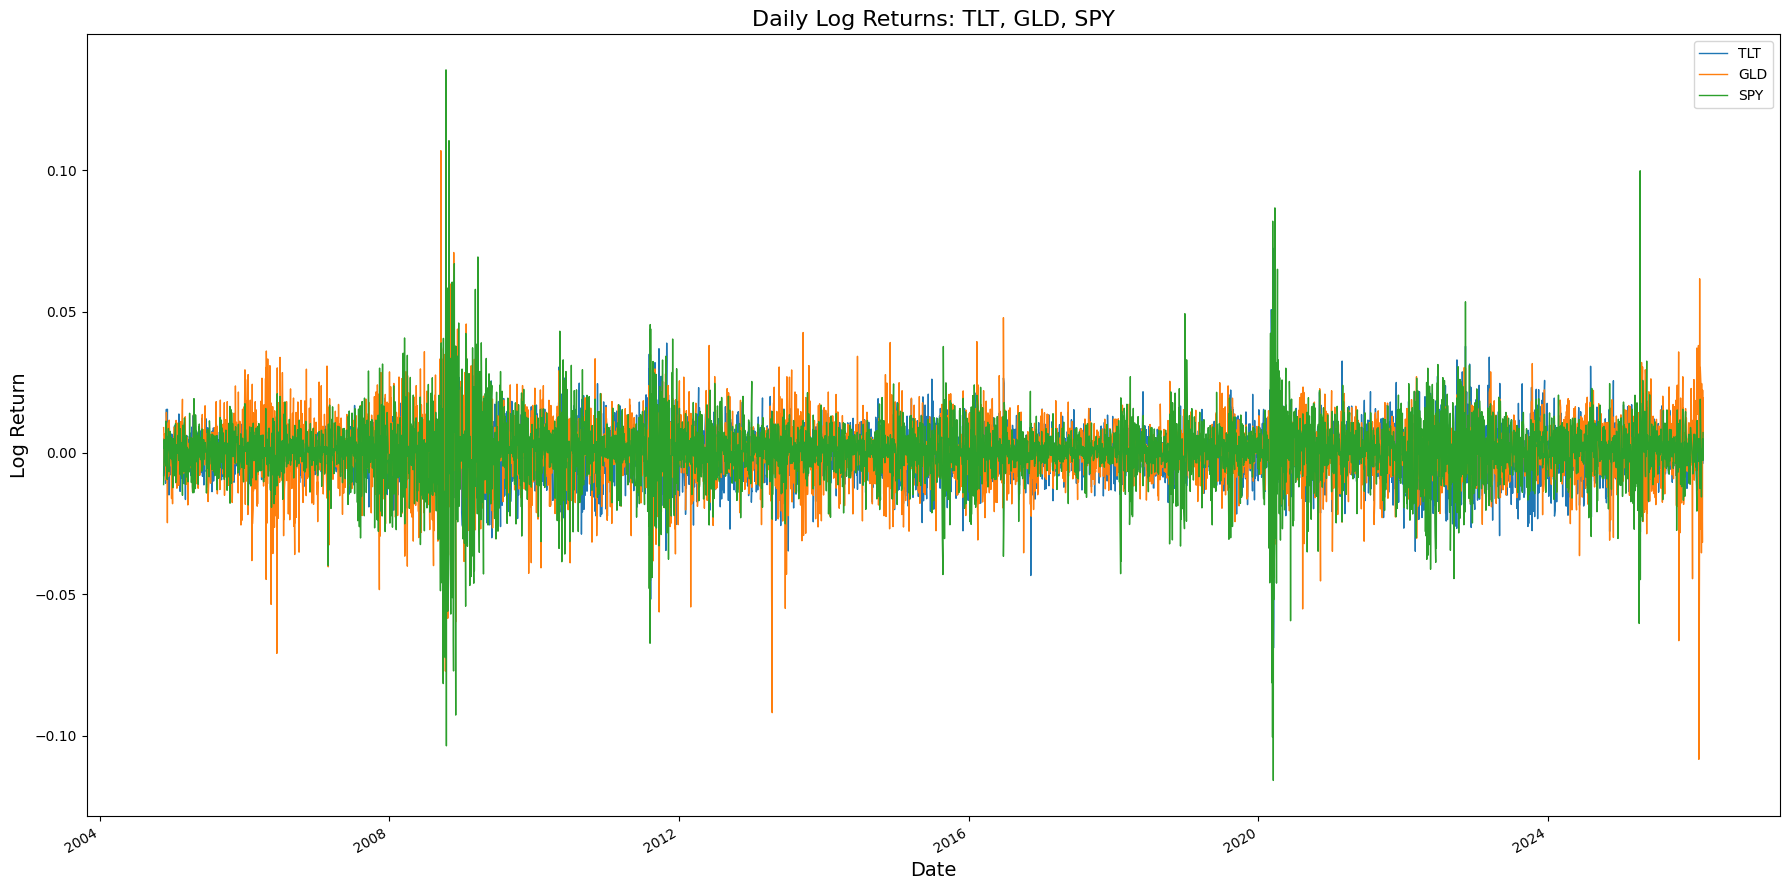

In [28]:
# ETF returns over time
ax = data_change[["TLT", "GLD", "SPY"]].plot(figsize=(18, 9), linewidth=1)

ax.set_title("Daily Log Returns: TLT, GLD, SPY", fontsize=16)
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Log Return", fontsize=14)

plt.tight_layout()
plt.show()

**Observations**

- All three series fluctuate around zero.
- In 2008 - 2009 we see that the return dispersion widens dramatically. Also in 2020 (Covid shock), the return dispersion widens.

- There were smaller clusters around 2011, 2018, 2022.
- SPY (green) has the largest spikes (both positive and negative)

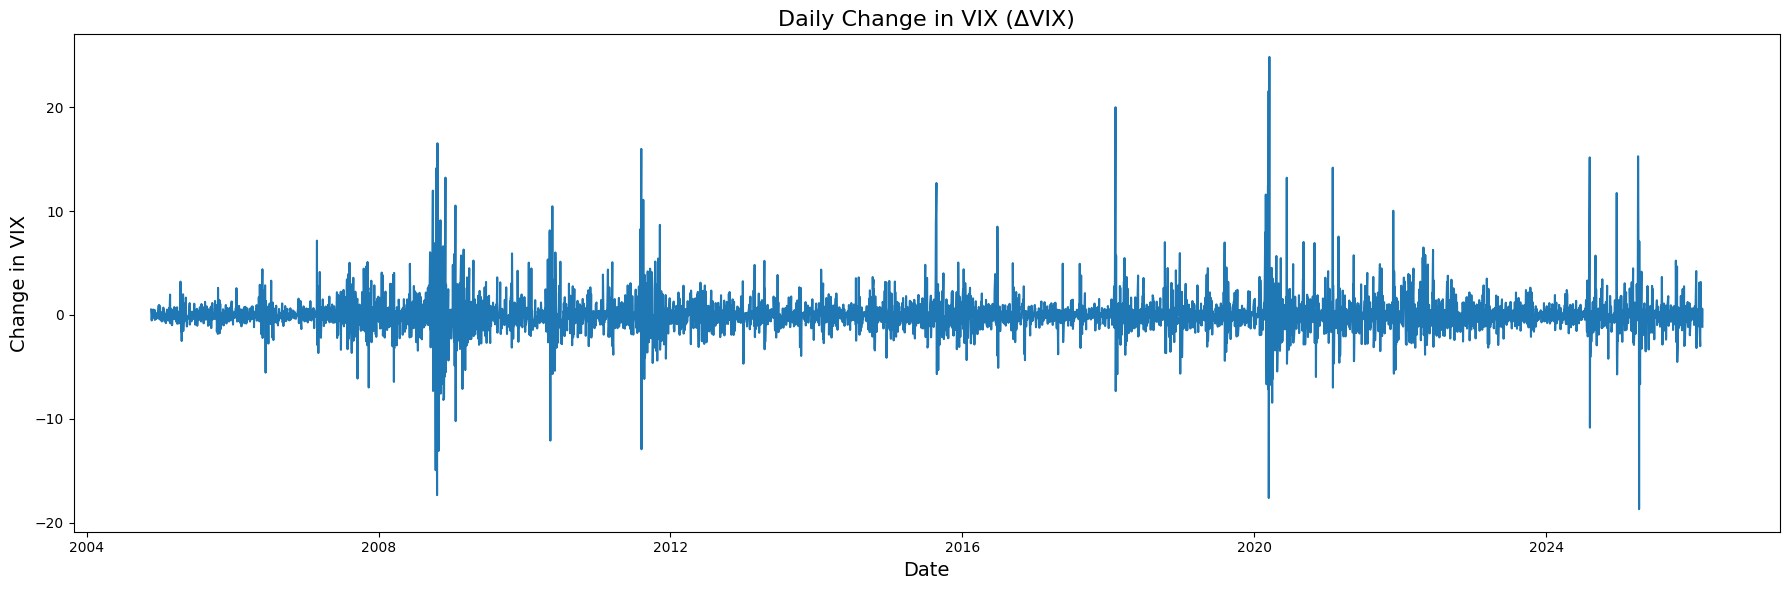

In [29]:
# ΔVIX (Volatility Changes)
plt.figure(figsize=(18, 6))
plt.plot(data_change.index, data_change["dVIX"])

plt.title("Daily Change in VIX (ΔVIX)", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Change in VIX", fontsize=14)

plt.tight_layout()
plt.show()


**Observations**
- VIX_change fluctuates around zero, indicating no long-term trend in daily change.
- Similarly as we saw earlier, there are large upward spikes occur during: 2008-2009 (Global Financial Crisis), and 2020 (COVID shock). These spikes represent sudden increases in implied volatility.
- Also we have smaller bursts in 2022-2024.

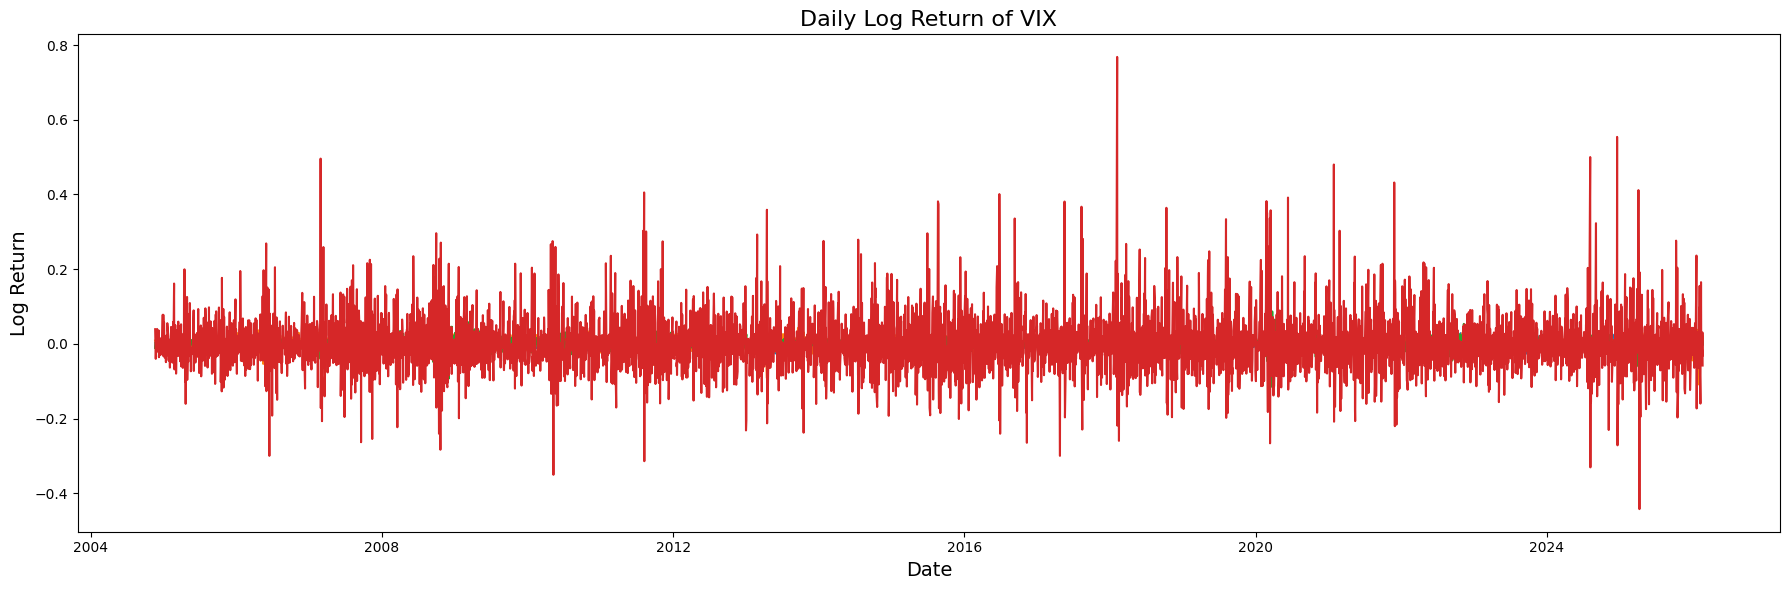

In [30]:
# Similary for ret_vix
plt.figure(figsize=(18, 6))
plt.plot(data_log_ret.index, data_log_ret.values)

plt.title("Daily Log Return of VIX", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Log Return", fontsize=14)

plt.tight_layout()
plt.show()


**Observations:**
- Similary, the log return of VIX fluctuates around zero.

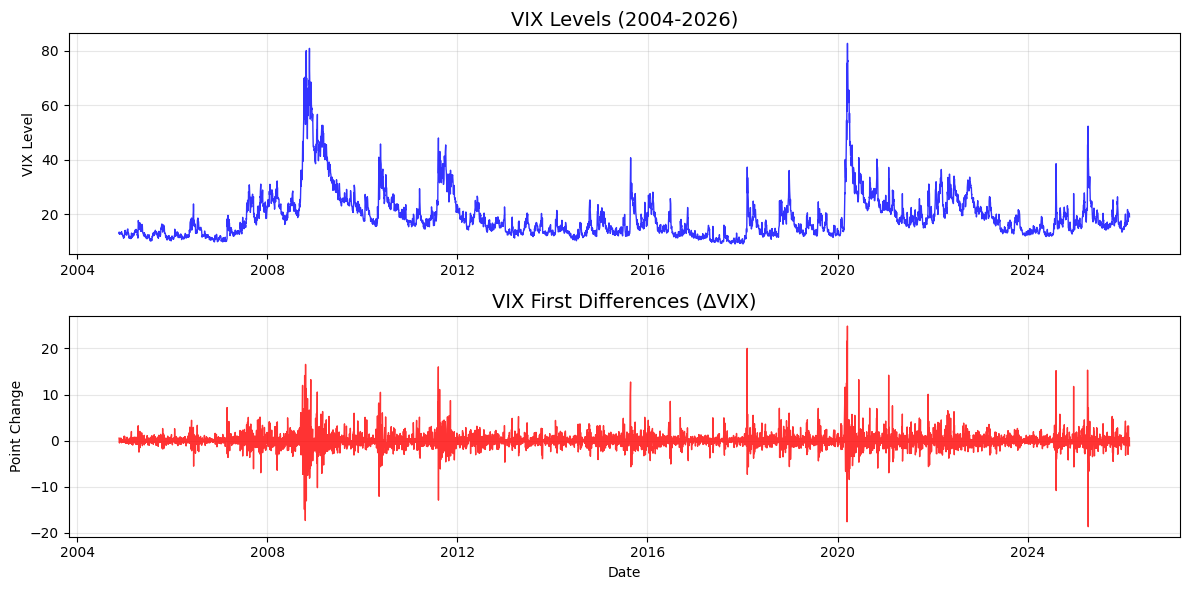

In [31]:
# Store as numpy array (handles both cases)
y = vix_change.squeeze().values  # or simply vix_change.values

# FIXED plots
plt.figure(figsize=(12, 6))

# Plot 1: VIX levels
plt.subplot(2, 1, 1)
plt.plot(px.index, px["^VIX"], 'b-', linewidth=1, alpha=0.8)
plt.title('VIX Levels (2004-2026)', fontsize=14)
plt.ylabel('VIX Level')
plt.grid(True, alpha=0.3)

# Plot 2: VIX changes (skip first NaN from diff())
plt.subplot(2, 1, 2)
plt.plot(px.index, vix_change, 'r-', linewidth=1, alpha=0.8)
plt.title('VIX First Differences (ΔVIX)', fontsize=14)
plt.ylabel('Point Change')
plt.xlabel('Date')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [32]:
print("VIX Level:", px["^VIX"].describe())
print("ΔVIX:", vix_change.dropna().describe())


VIX Level: count    5347.000000
mean       19.096379
std         8.613840
min         9.140000
25%        13.420000
50%        16.690001
75%        21.990000
max        82.690002
Name: ^VIX, dtype: float64
ΔVIX: count    5346.000000
mean        0.001143
std         1.906269
min       -18.710003
25%        -0.720000
50%        -0.090000
75%         0.560001
max        24.860001
Name: dVIX, dtype: float64


- **VIX Level**: Max 82.69 was 2008 financial crisis.
- **ΔVIX (daily change)**: Average change = almost 0 (doesn't trend up/down). But big spikes happen:
  - Biggest jump: **+25 points** (fear explodes)
  - Biggest drop: **-19 points** (fear vanishes)

We can say that VIX jumps UP much more dramatically than it falls, i.e., crash risk is asymmetric.

## Step 2: Modeling VIX Regimes

We recall that the objective of Step 1 is to construct a clean and consistent dataset suitable for regime-switching modeling.

We did this by aligning all assets on a common sample period and transforming prices into stationary log returns and volatility changes, this will ensure statistical validity and comparability across series.

In this step, we want to infer volatility regimes from the daily change in VIX (ΔVIX) and represent regime dynamics using either:


1.   a discrete Markov chain (observable regimes), or
2.   a Hidden Markov Model (HMM) (latent regimes inferred probabilistically).

In [33]:
# ΔVIX series (observation for regime modeling)
y = data_change["dVIX"]
idx = y.index

In [34]:
# Extract aligned index and VIX level
Y = y.values.astype(float)
vix_level = px["^VIX"].loc[idx]

### Discrete Markov Chain Option

**Definition**: A sequence of random variables $(S_0,S_1,S_2,...)$ is a Markov chain with state space $S$ and transition matrix $P$ if, for all $t\geq 0$ and all sequences $(s_0,s_1,s_2,...,s_t,s_{t+1})$, we have that $\mathbb{P}(S_{t+1}|s_{t},s_{t-1},...,s_{1},s_{0})=\mathbb{P}(S_{t+1}|s_{t})$.

A discrete Markov chain provides a transparent description of how often markets move between calm and stressed volatility-shock states, and how persistent each regime is.

- Discretize ΔVIX into 2-3 states (quantiles)

First, we want to convert a continuous variable (ΔVIX) into $K$ discrete states using quantiles. This is done using the `discretize_quantiles` function.


In [35]:
def discretize_quantiles(series: pd.Series, K: int) -> pd.Series:
    """Discretize series into K quantile-based states labeled 0..K-1."""
    return pd.qcut(series, q=K, labels=False).astype(int)

We used `pd.qcut` to discretize ΔVIX into $K$ quantile-based states, this ensures approximately equal numbers of observations per regime.

Next, we estimate the transition matrix using the function `estimate_transition_matrix`, this allows to quantify regime persistence and compute the stationary distribution.

The transition matrix is estimated using maximum likelihood by counting empirical state-to-state transitions.

In [36]:
def estimate_transition_matrix(states: np.ndarray, K: int) -> np.ndarray:
    """Estimate KxK transition matrix from integer state sequence."""
    counts = np.zeros((K, K), dtype=float)
    for t in range(len(states) - 1):
        counts[states[t], states[t + 1]] += 1
    P = counts / counts.sum(axis=1, keepdims=True)
    return P

Recall that for a Markov chain with transition matrix $P$, the stationary distribution
$\pi$ satisfies:
$$
\pi = \pi P,
$$
where $$\sum_i \pi_i =1$$

The stationary distribution is computed as the eigenvector of the transposed transition matrix associated with eigenvalue 1.

In [37]:
def stationary_distribution(P: np.ndarray) -> np.ndarray:
    """Stationary distribution pi solving pi = pi P."""
    eigvals, eigvecs = np.linalg.eig(P.T)
    k = np.argmin(np.abs(eigvals - 1.0))
    pi = np.real(eigvecs[:, k])
    pi = pi / pi.sum()
    return pi


Next, we create a function that plots VIX with color-coded states

In [38]:
def plot_vix_colored(dates, vix, states, title):
    plt.figure(figsize=(18, 6))
    plt.scatter(dates, vix, c=states, s=6)
    plt.title(title, fontsize=16)
    plt.xlabel("Date", fontsize=14)
    plt.ylabel("VIX", fontsize=14)
    plt.tight_layout()
    plt.show()

**Implementation**


Discrete Markov Chain on ΔVIX quantile states (K=2)
Transition matrix P:
          S0        S1
S0  0.485097  0.514903
S1  0.519729  0.480271
Stationary distribution pi:
S0    0.502332
S1    0.497668
Name: pi, dtype: float64


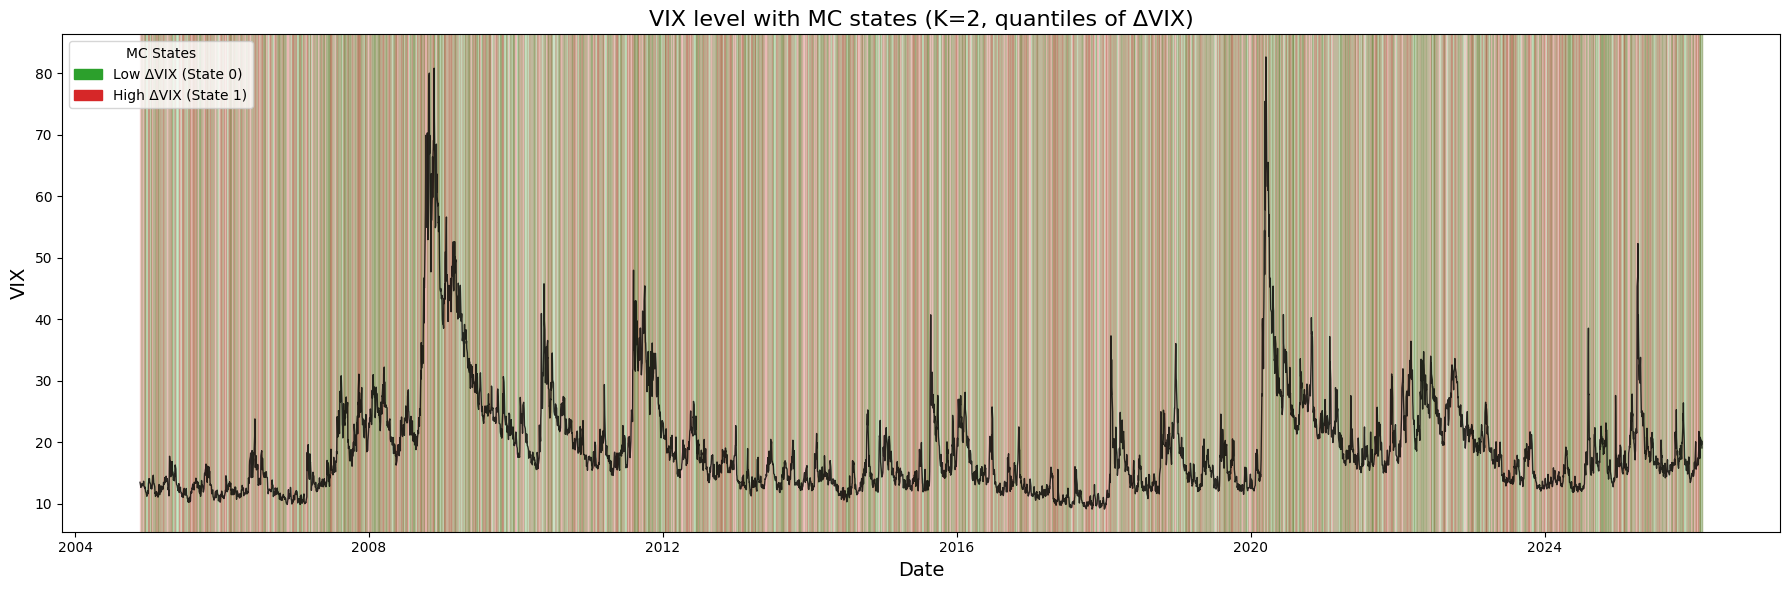


Discrete Markov Chain on ΔVIX quantile states (K=3)
Transition matrix P:
          S0        S1        S2
S0  0.349944  0.305151  0.344905
S1  0.234436  0.429613  0.335951
S2  0.418919  0.265766  0.315315
Stationary distribution pi:
S0    0.334318
S1    0.333591
S2    0.332091
Name: pi, dtype: float64


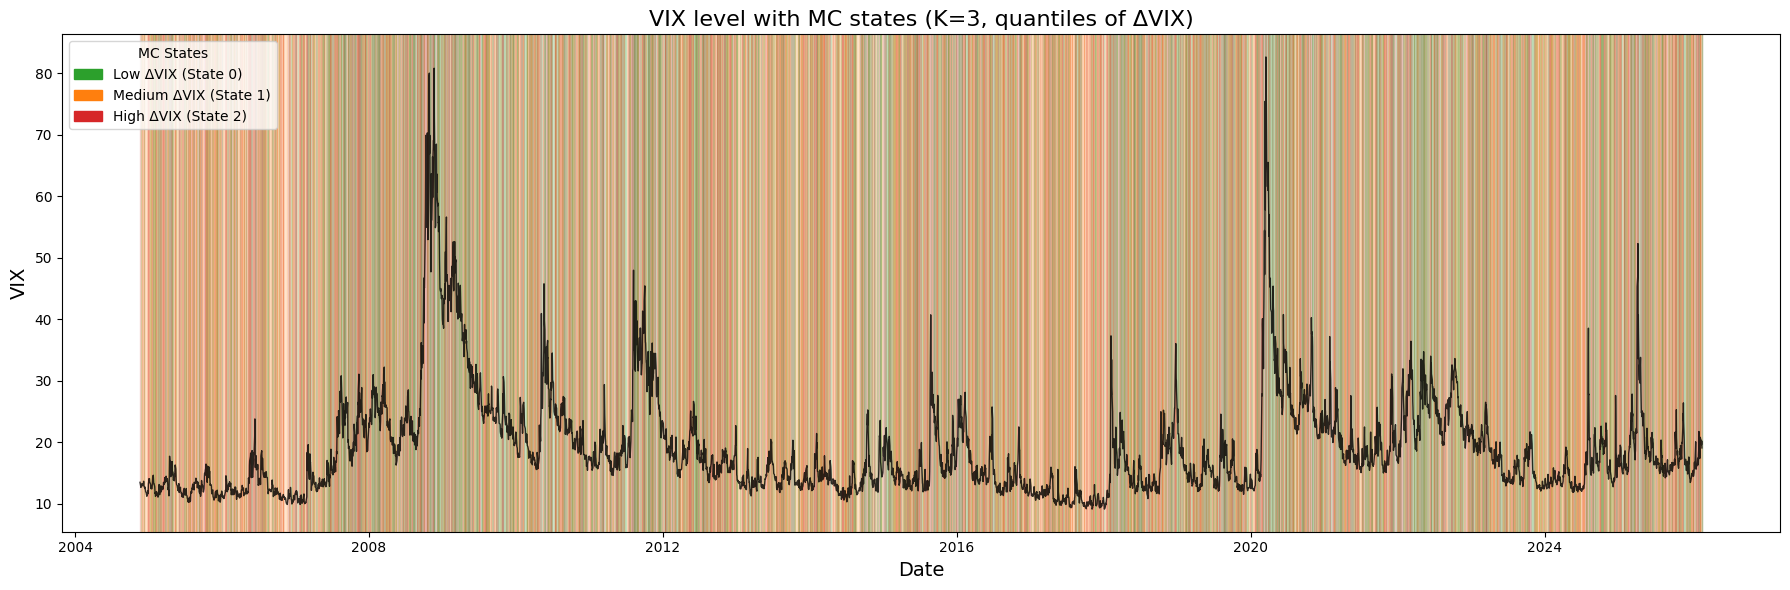

In [39]:
# Run discrete MC for K=2 and K=3
for K in [2, 3]:
    mc_state = discretize_quantiles(y, K)
    P_mc = estimate_transition_matrix(mc_state.values, K)
    pi_mc = stationary_distribution(P_mc)

    print(f"\nDiscrete Markov Chain on ΔVIX quantile states (K={K})")
    print("Transition matrix P:")
    print(pd.DataFrame(P_mc, index=[f"S{i}" for i in range(K)], columns=[f"S{j}" for j in range(K)]))
    print("Stationary distribution pi:")
    print(pd.Series(pi_mc, index=[f"S{i}" for i in range(K)], name="pi"))

    plt.figure(figsize=(18, 6))

    # Plot VIX level as a line
    plt.plot(idx, vix_level.values, 'k-', linewidth=1, alpha=0.8, zorder=2)

    # Define colors and labels for the regimes based on K
    if K == 2:
        regime_colors = {0: '#2ca02c', 1: '#d62728'}
        regime_labels = {0: 'Low ΔVIX (State 0)', 1: 'High ΔVIX (State 1)'}
    else: # K == 3
        regime_colors = {0: '#2ca02c', 1: '#ff7f0e', 2: '#d62728'}
        regime_labels = {0: 'Low ΔVIX (State 0)', 1: 'Medium ΔVIX (State 1)', 2: 'High ΔVIX (State 2)'}

    # Plot regime stripes using axvspan
    current_state = mc_state.values[0]
    start_date_of_regime = idx[0]

    for i in range(1, len(mc_state.values)):
        if mc_state.values[i] != current_state:
            plt.axvspan(start_date_of_regime, idx[i-1], color=regime_colors[current_state], alpha=0.2, zorder=1)
            current_state = mc_state.values[i]
            start_date_of_regime = idx[i]

    # Plot the last regime segment
    plt.axvspan(start_date_of_regime, idx[-1], color=regime_colors[current_state], alpha=0.2, zorder=1)

    # Create a custom legend for the colored stripes
    legend_patches = []
    for i in sorted(regime_labels.keys()):
        patch = mpatches.Patch(color=regime_colors[i], label=regime_labels[i])
        legend_patches.append(patch)

    plt.legend(handles=legend_patches, title="MC States", loc='upper left')

    plt.title(f"VIX level with MC states (K={K}, quantiles of ΔVIX)", fontsize=16)
    plt.xlabel("Date", fontsize=14)
    plt.ylabel("VIX", fontsize=14)
    plt.tight_layout()
    plt.show()

The **quantile-based discrete Markov chain** produces low regime persistence and nearly equal stationary probabilities by construction.

Expected regime durations are approximately 1-2 days, indicating frequent switching.

This suggests that simple discretization of ΔVIX fails to capture volatility clustering.

---

Next, we implement the Hidden Markov Model (HMM).
### Hidden Markov Model Option

- Fit 2- and 3-state Gaussian HMMs to ∆VIX using the EM algorithm.

First, we create a function that computes the emission density, i.e., the likelihood of the observation under state $i$.

In [40]:
def emission_prob(y_t, mu, sigma):
    """f(y_t | s_t=i)"""
    return norm.pdf(y_t, loc=mu, scale=sigma)

Next, we define the Hamiton filter.

The Hidden Markov Model is estimated using the Hamilton filter, which implements a forward recursion to compute the likelihood and filtered state probabilities. At each time step, the algorithm first predicts the probability of each regime based on the previous filtered probabilities and the transition matrix.

It then updates these probabilities using Bayes' rule by weighting the predicted probabilities with the Gaussian emission density of the observed ΔVIX

In [41]:
def hamilton_filter(Y, mu, sigma, P, pi):
    """
    Hamilton filter (forward recursion).

    Returns:
      filtered_probs[t,i]  = P(s_t=i | y_1:t)
      predicted_probs[t,i] = P(s_t=i | y_1:t-1)  (t=0 is prior pi)
      log_likelihood
      marginal_likelihoods[t] = p(y_t | y_1:t-1)
    """
    T = len(Y)
    K = len(mu)

    filtered_probs = np.zeros((T, K))
    predicted_probs = np.zeros((T, K))
    marginal_likelihoods = np.zeros(T)

    predicted_probs[0] = pi

    for t in range(T):
        # compute emission likelihoods for each state
        emissions = np.array([emission_prob(Y[t], mu[i], sigma[i]) for i in range(K)])
        # compute the marginal likelihood of the observation
        marginal_likelihoods[t] = np.sum(predicted_probs[t] * emissions)

        # Bayes update
        filtered_probs[t] = (predicted_probs[t] * emissions) / (marginal_likelihoods[t] + 1e-300)

        # predict next
        if t < T - 1:
            predicted_probs[t + 1] = P.T @ filtered_probs[t]

    log_likelihood = np.sum(np.log(marginal_likelihoods + 1e-300))
    return filtered_probs, predicted_probs, log_likelihood, marginal_likelihoods

Starting with 2-state Gaussian HMM parameterization, we want to estimate the paramenters

$$\mu_1, \mu_2, \sigma_1, \sigma_2, p_{11}, p_{22}, \pi_1$$ by maximum likelihood.

In [42]:
def negative_log_likelihood(params, Y):
    """
    2-state Gaussian HMM parameterization:
      params = [mu1, mu2, sigma1, sigma2, p11, p22, pi1]
    """
    mu1, mu2, sigma1, sigma2, p11, p22, pi1 = params

    # Constraints (ΔVIX scale => do NOT force sigma < 1)
    if sigma1 <= 0 or sigma2 <= 0:
        return 1e10
    if sigma1 > 1e3 or sigma2 > 1e3:
        return 1e10
    if not (0 <= p11 <= 1) or not (0 <= p22 <= 1):
        return 1e10
    if not (0 <= pi1 <= 1):
        return 1e10

    mu = np.array([mu1, mu2])
    sigma = np.array([sigma1, sigma2])
    P = np.array([[p11, 1 - p11],
                  [1 - p22, p22]])
    pi = np.array([pi1, 1 - pi1])

    try:
        _, _, ll, _ = hamilton_filter(Y, mu, sigma, P, pi)
        return -ll
    except Exception:
        return 1e10


The negative log-likelihood function maps a parameter vector into the negative log-likelihood computed via the Hamilton filter.

---

Next, we create a function that takes our negative log-likelihood and solves the maximum likelihood problem.

We want to compute

$$
\hat{\theta} = \arg\max_{\theta} \log p(Y \mid \theta)
$$
The function chooses starting values, the calls a numerical optimizer and then extracts estimated parametersand returns them in usable matrix form.

Let's run our Expectation-Maximization (EM) algorithm to estimate these parameters (this could take some time):

In [43]:
def estimate_mle(Y, initial_guess=None):
    if initial_guess is None:
        # reasonable ΔVIX starting values
        initial_guess = [np.percentile(Y, 40), np.percentile(Y, 70),
                         np.std(Y), np.std(Y)*2,
                         0.95, 0.90,
                         0.5]

    res = minimize(negative_log_likelihood, initial_guess, args=(Y,), method="BFGS")

    mu1, mu2, s1, s2, p11, p22, pi1 = res.x
    mu = np.array([mu1, mu2])
    sigma = np.array([s1, s2])
    P = np.array([[p11, 1 - p11],
                  [1 - p22, p22]])
    pi = np.array([pi1, 1 - pi1])

    max_ll = -res.fun
    return mu, sigma, P, pi, max_ll, res

mu_est, sigma_est, P_est, pi_est, ll_est, opt_res = estimate_mle(Y)
print("mu:", mu_est)
print("sigma:", sigma_est)
print("P:\n", P_est)
print("pi:", pi_est)
print("loglik:", ll_est)


mu: [-0.06267218  0.19606264]
sigma: [0.80680644 3.47395213]
P:
 [[0.97037602 0.02962398]
 [0.07170896 0.92829104]]
pi: [0.95960493 0.04039507]
loglik: -9103.748362760154


**Observations**:

- State 0 has a slightly negative mean change in VIX ($\mu_0 \approx -0.063$) with low dispersion ($\sigma_1 \approx 0.807$), consistent with a calm / mean-reverting volatility environment.
- State 1 has a strongly positive mean ($\mu_1
 \approx 0.196$) and much higher dispersion ($\sigma_1 \approx 3.47$), consistent with a stress / volatility-shock regime.

- The log-likelihood ($-9103.74$) can be used to compare against alternative specifications.



---

Now with these estimated parameters we can re-run the Hamilton filter to obtain, at each date $t$, the predicted probabilities of a regime ocurring next date ($t+1$). Specifically, using the Hamilton filter we will next compute:

1. **Filtered probabilities** ($Pr(s_t = i | y_{1:t})$): These are *posterior probabilities*, in the sense that they tell us how likely is that we are in state $s$ today given all data up to today.

2. **Predicted probabilities** ($Pr(s_t = i | y_{1:t-1})$): These are *prior probabilities*, as they use the transition matrix to inform us about the change of being in state $s$ today given what we know until yesterday.

3. **Smoothed probabilities** ($Pr(s_t = i | y_{1:T}$): These are the probabilities of being in regime $i$ at time $t$, conditional on the entire sample, including future observations. They are obtained via the **forward-backward (Kim) smoothing recursion**.

In [44]:
def kim_smoother(filtered_probs, predicted_probs, P):
    """
    Backward recursion to compute smoothed probabilities:
      smoothed[t] = P(s_t | y_1:T)
    """
    T, K = filtered_probs.shape
    smoothed = np.zeros_like(filtered_probs)
    smoothed[-1] = filtered_probs[-1]

    for t in range(T - 2, -1, -1):
        denom = predicted_probs[t + 1] + 1e-300
        adj = P @ (smoothed[t + 1] / denom)
        smoothed[t] = filtered_probs[t] * adj
        smoothed[t] /= smoothed[t].sum()
    return smoothed

filtered, predicted, ll, _ = hamilton_filter(Y, mu_est, sigma_est, P_est, pi_est)
smoothed = kim_smoother(filtered, predicted, P_est)

# Most likely state sequence from smoothed probs (for plotting/interpretation only)
z_hat = smoothed.argmax(axis=1)

# Filtered state sequence — no future data (for backtesting use only)
z_filtered_2state = filtered.argmax(axis=1)


Extract the most likely state sequence and smoothed probabilities.

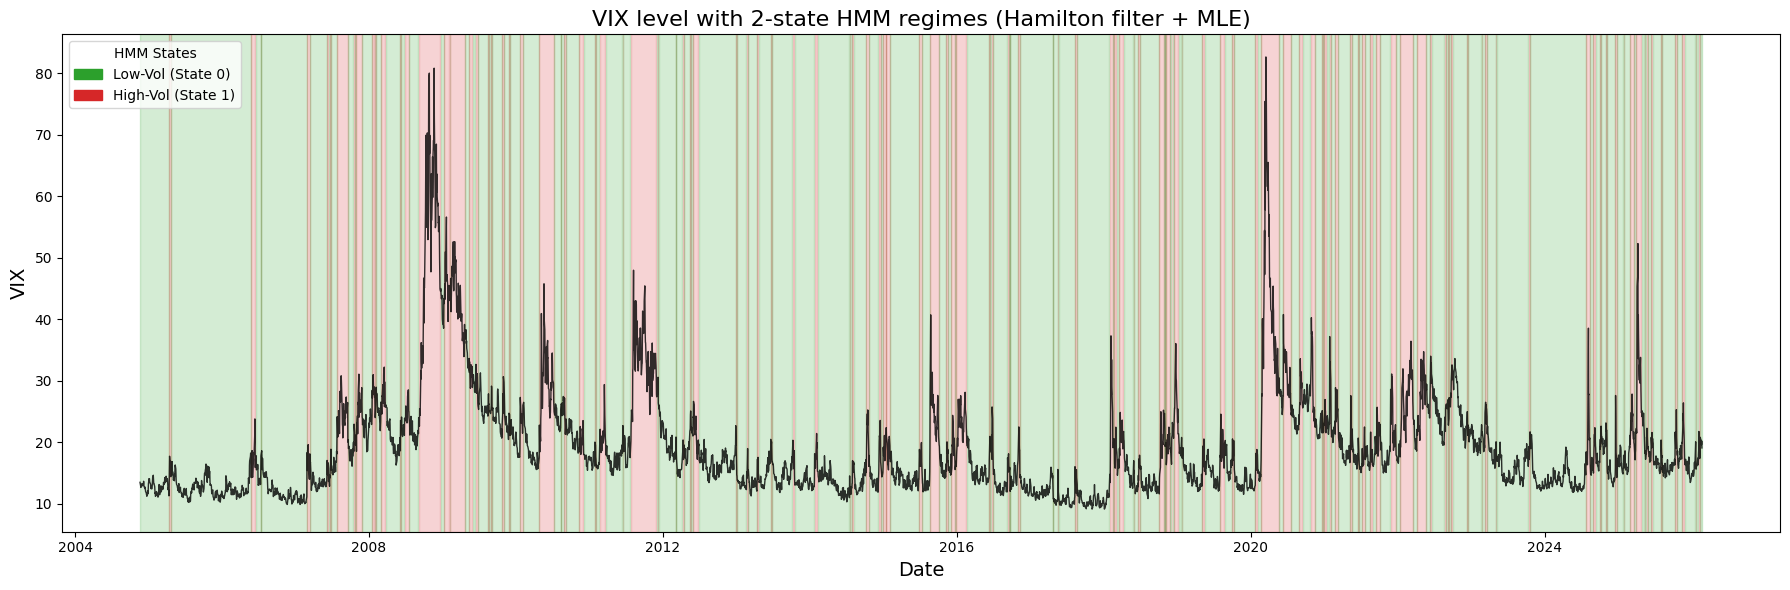

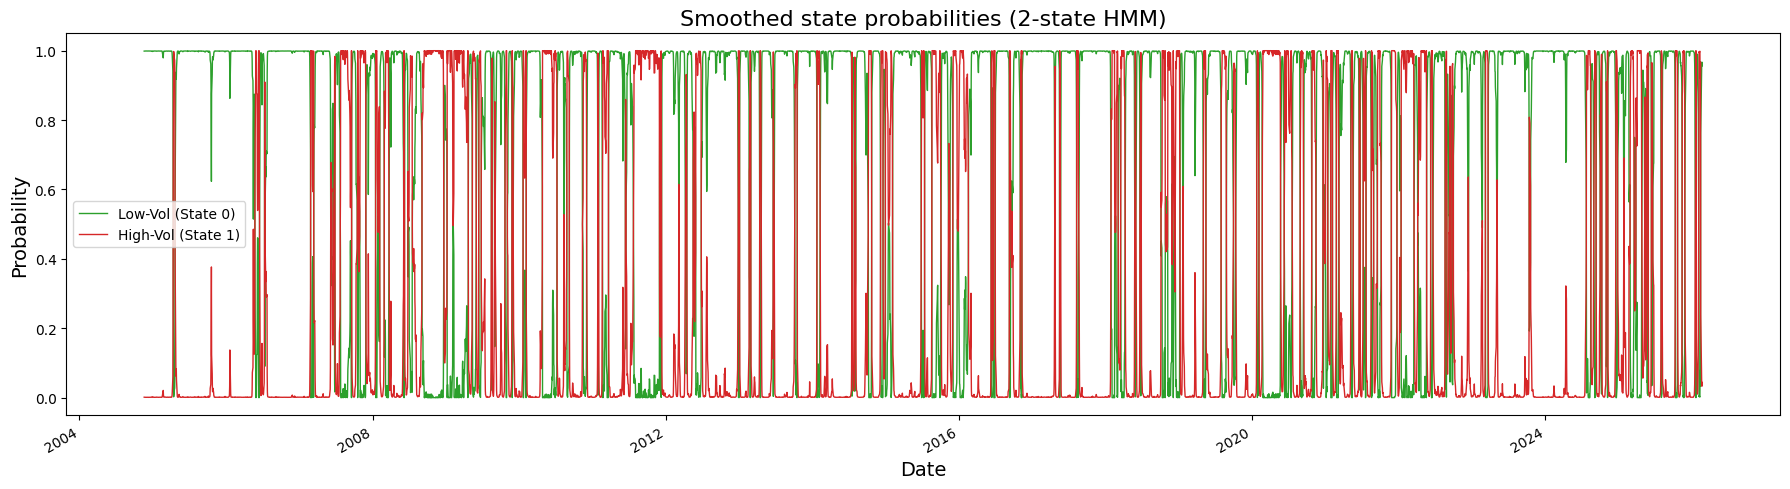

In [45]:
import matplotlib.patches as mpatches

# Define colors and labels for the regimes
regime_colors = {0: '#2ca02c', 1: '#d62728'}
regime_labels = {0: 'Low-Vol (State 0)', 1: 'High-Vol (State 1)'}

plt.figure(figsize=(18, 6))

# Plot VIX level as a line
plt.plot(idx, vix_level.values, 'k-', linewidth=1, alpha=0.8, zorder=2)

# Plot regime stripes using axvspan
current_state = z_hat[0]
start_date_of_regime = idx[0]

for i in range(1, len(z_hat)):
    if z_hat[i] != current_state:
        plt.axvspan(start_date_of_regime, idx[i-1], color=regime_colors[current_state], alpha=0.2, zorder=1)
        current_state = z_hat[i]
        start_date_of_regime = idx[i]

# Plot the last regime segment
plt.axvspan(start_date_of_regime, idx[-1], color=regime_colors[current_state], alpha=0.2, zorder=1)

# Create a custom legend for the colored stripes
legend_patches = []
for i in sorted(regime_labels.keys()):
    patch = mpatches.Patch(color=regime_colors[i], label=regime_labels[i])
    legend_patches.append(patch)

plt.legend(handles=legend_patches, title="HMM States", loc='upper left')

plt.title("VIX level with 2-state HMM regimes (Hamilton filter + MLE)", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("VIX", fontsize=14)
plt.tight_layout()
plt.show()

# Smoothed probabilities plot (unchanged from previous intent)
gamma_df = pd.DataFrame(smoothed, index=idx, columns=[regime_labels[i] for i in sorted(regime_labels.keys())])
ax = gamma_df.plot(figsize=(18, 5), linewidth=1, color=[regime_colors[i] for i in sorted(regime_colors.keys())])
ax.set_title("Smoothed state probabilities (2-state HMM)", fontsize=16)
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Probability", fontsize=14)
plt.tight_layout()
plt.show()

---
Next, we implement for K=3

The EM algorithm for HMMs requires repeated evaluation of forward-backward probabilities over thousands of observations. To avoid numerical underflow when multiplying many small probabilities, computations are performed in log-space.

Hence, we create a `logsumexp` function which provides a numerically stable way to compute
$$ \log \sum_i e^{a_i} $$
by factoring out the maximum value before exponentiation.

In [46]:
# log-space for stability
def logsumexp(a, axis=None):
    a = np.asarray(a)
    amax = np.max(a, axis=axis, keepdims=True)
    out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))
    if axis is not None:
        out = np.squeeze(out, axis=axis)
    return out

In [47]:
# Similarly, using log-space
def log_emission_probs(Y, mu, sigma):
    """
    logB[t,i] = log p(Y_t | state=i) for 1D Gaussian emissions.
    Y: (T,)
    mu: (K,)
    sigma: (K,)
    """
    T = len(Y)
    K_local = len(mu)
    logB = np.empty((T, K_local))
    for i in range(K_local):
        logB[:, i] = norm.logpdf(Y, loc=mu[i], scale=sigma[i])
    return logB


For the next funtion the goal is that given current parameters $\theta = (\pi,P,\mu,\sigma)$, we want to compute the posterior probabilities of the hidden states. Again, we work in log-space for numerical stability.

In [48]:
# E-step: Forward-Backward (returns gamma, xi, loglik)
def forward_backward_log(Y, pi, P, mu, sigma):
    """
    Forward-backward in log-space.

    Returns:
      gamma: (T,K) smoothed probs P(s_t=i | y_1:T)
      xi:    (T-1,K,K) expected transitions P(s_t=i, s_{t+1}=j | y_1:T)
      loglik: scalar log-likelihood
    """
    T = len(Y)

    logPi = np.log(pi + 1e-300)
    logP  = np.log(P  + 1e-300)
    logB  = log_emission_probs(Y, mu, sigma)  # (T,K)

    # Forward pass: logAlpha
    logAlpha = np.empty((T, K))
    logAlpha[0] = logPi + logB[0]
    for t in range(1, T):
        # logAlpha[t,j] = logB[t,j] + logsum_i (logAlpha[t-1,i] + logP[i,j])
        logAlpha[t] = logB[t] + logsumexp(logAlpha[t-1][:, None] + logP, axis=0)

    loglik = float(logsumexp(logAlpha[-1], axis=0))

    # Backward pass: logBeta
    logBeta = np.empty((T, K))
    logBeta[-1] = 0.0
    for t in range(T-2, -1, -1):
        # logBeta[t,i] = logsum_j (logP[i,j] + logB[t+1,j] + logBeta[t+1,j])
        logBeta[t] = logsumexp(logP + logB[t+1][None, :] + logBeta[t+1][None, :], axis=1)

    # Smoothed state probs: gamma
    logGamma = logAlpha + logBeta
    logGamma = logGamma - logsumexp(logGamma, axis=1)[:, None]
    gamma = np.exp(logGamma)

    # Smoothed transition probs: xi
    xi = np.empty((T-1, K, K))
    for t in range(T-1):
        logXi = (logAlpha[t][:, None] + logP + logB[t+1][None, :] + logBeta[t+1][None, :])
        logXi = logXi - logsumexp(logXi, axis=None)
        xi[t] = np.exp(logXi)

    return gamma, xi, loglik

Next, we have to update the paramenters to maximize the expected complete-data log likelihood $\pi, P, \mu, \sigma$ using $\gamma$ and $\xi$ fromm the E-step.

In [49]:

# M-step: Update pi, P, mu, sigma
def m_step(Y, gamma, xi, min_sigma=1e-6):
    """
    Closed-form M-step for 1D Gaussian HMM.
    """
    T = len(Y)

    # Initial distribution
    pi_new = gamma[0].copy()
    pi_new /= pi_new.sum()

    # Transition matrix
    xi_sum = xi.sum(axis=0)            # (K,K)
    gamma_sum = gamma[:-1].sum(axis=0) # (K,)
    P_new = xi_sum / (gamma_sum[:, None] + 1e-300)
    P_new = np.clip(P_new, 1e-300, 1.0)
    P_new /= P_new.sum(axis=1, keepdims=True)

    # Means
    gamma_tot = gamma.sum(axis=0)      # (K,)
    mu_new = (gamma * Y[:, None]).sum(axis=0) / (gamma_tot + 1e-300)

    # Standard deviations
    var_new = (gamma * (Y[:, None] - mu_new[None, :])**2).sum(axis=0) / (gamma_tot + 1e-300)
    sigma_new = np.sqrt(np.maximum(var_new, min_sigma**2))

    return pi_new, P_new, mu_new, sigma_new

We need to initialization since EM can converge to local maxima.

In [50]:
def init_params(Y, K=3, seed=1):
    rng = np.random.default_rng(seed)

    # Quantile means (spreads states across distribution)
    qs = np.linspace(0.1, 0.9, K)
    mu = np.quantile(Y, qs)

    # Same starting sigma for all states (global std)
    s = np.std(Y) if np.std(Y) > 0 else 1.0
    sigma = np.full(K, s)

    # Persistent transition matrix (diagonal-heavy)
    P = np.full((K, K), 1.0 / K)
    np.fill_diagonal(P, 0.90)
    P /= P.sum(axis=1, keepdims=True)

    # Uniform initial probs
    pi = np.full(K, 1.0 / K)

    # Small jitter to avoid symmetry issues
    mu = mu + 0.01 * rng.standard_normal(K) * s

    return pi, P, mu, sigma

Now, we want to estimate the HMM parameters $\theta = (\pi,P,\mu,\sigma)$ by iterating:

- E-step: compute $\gamma_t(i)$ and $\xi_t(i,j)$ using forward-backward

- M-step: update
$\pi,P,\mu,\sigma$ using closed-form formulas

In [51]:
def fit_gaussian_hmm_em(Y, K=3, max_iter=300, tol=1e-6, seed=1, verbose=True):
    pi, P, mu, sigma = init_params(Y, K=K, seed=seed)
    prev_ll = -np.inf
    ll_hist = []

    for it in range(max_iter):
        gamma, xi, ll = forward_backward_log(Y, pi, P, mu, sigma)
        ll_hist.append(ll)

        pi, P, mu, sigma = m_step(Y, gamma, xi)

        if verbose and (it % 10 == 0 or it == max_iter - 1):
            print(f"EM iter {it:3d} | loglik = {ll:.6f}")

        # relative-ish convergence check
        if np.isfinite(prev_ll) and abs(ll - prev_ll) < tol * (1 + abs(prev_ll)):
            if verbose:
                print(f"Converged at iter {it} | loglik = {ll:.6f}")
            break

        prev_ll = ll

    # Final E-step outputs
    gamma, xi, ll = forward_backward_log(Y, pi, P, mu, sigma)

    return {"pi": pi, "P": P, "mu": mu, "sigma": sigma, "gamma": gamma, "loglik": ll, "ll_hist": ll_hist}


In [52]:
def viterbi_path(Y, pi, P, mu, sigma):
    T = len(Y)
    K = len(pi)

    logPi = np.log(pi + 1e-300)
    logP  = np.log(P  + 1e-300)
    logB  = log_emission_probs(Y, mu, sigma)

    delta = np.empty((T, K))
    psi = np.empty((T, K), dtype=int)

    delta[0] = logPi + logB[0]
    psi[0] = 0

    for t in range(1, T):
        scores = delta[t-1][:, None] + logP
        psi[t] = np.argmax(scores, axis=0)
        delta[t] = logB[t] + np.max(scores, axis=0)

    z = np.empty(T, dtype=int)
    z[-1] = np.argmax(delta[-1])
    for t in range(T-2, -1, -1):
        z[t] = psi[t+1, z[t+1]]
    return z

Observe that HMM states are unlabeled, i.e., EM could call “crisis” state 0 in one run and state 2 in another. The likelihood is the same.

In [53]:
def relabel_by_mu(params_dict):
    mu = params_dict["mu"]
    order = np.argsort(mu)  # low mean ΔVIX -> high mean ΔVIX
    inv = np.zeros_like(order)
    inv[order] = np.arange(len(order))

    params_dict["mu"] = params_dict["mu"][order]
    params_dict["sigma"] = params_dict["sigma"][order]
    params_dict["pi"] = params_dict["pi"][order]
    params_dict["P"] = params_dict["P"][order][:, order]
    params_dict["gamma"] = params_dict["gamma"][:, order]

    return params_dict, inv  # inv remaps old state labels to new labels


Putting it togethe. We have

In [54]:
fit3 = fit_gaussian_hmm_em(Y, K=3, max_iter=300, tol=1e-6, seed=1, verbose=True)
fit3, inv = relabel_by_mu(fit3)

# Viterbi path using relabeled parameters (for plotting/interpretation only)
z3 = viterbi_path(Y, fit3["pi"], fit3["P"], fit3["mu"], fit3["sigma"])

# Smoothed probabilities (already computed inside EM — uses full sample, for plots only)
gamma3 = fit3["gamma"]

# ── BIAS FIX: compute filtered probabilities via forward pass only ──
# filtered3[t] = P(s_t=i | y_1:t)  — uses NO future information
K3 = 3
logPi3 = np.log(fit3["pi"] + 1e-300)
logP3  = np.log(fit3["P"]  + 1e-300)
logB3  = log_emission_probs(Y, fit3["mu"], fit3["sigma"])

logAlpha3 = np.empty((len(Y), K3))
logAlpha3[0] = logPi3 + logB3[0]
for t in range(1, len(Y)):
    logAlpha3[t] = logB3[t] + logsumexp(logAlpha3[t-1][:, None] + logP3, axis=0)

# Normalize rows to get filtered probabilities
logAlpha3_norm = logAlpha3 - logsumexp(logAlpha3, axis=1)[:, None]
filtered3 = np.exp(logAlpha3_norm)

# State sequence from filtered probs — use THIS for backtesting (no lookahead bias)
z3_filtered = filtered3.argmax(axis=1)

# Print parameters (deliverable)
print("\n=== 3-state Gaussian HMM (K=3) fitted by EM ===")
print("mu:   ", fit3["mu"])
print("sigma:", fit3["sigma"])
print("pi:   ", fit3["pi"])
print("P:\\n", fit3["P"])
print("loglik:", fit3["loglik"])
print("\nFiltered state distribution (no future info):", np.bincount(z3_filtered))
print("Smoothed state distribution (full sample):", np.bincount(z3))


EM iter   0 | loglik = -11424.242174
EM iter  10 | loglik = -8796.248907
EM iter  20 | loglik = -8746.472070
Converged at iter 22 | loglik = -8746.454644

=== 3-state Gaussian HMM (K=3) fitted by EM ===
mu:    [-0.05976417 -0.01445445  0.62889794]
sigma: [0.61293418 1.72970545 5.95165971]
pi:    [1.00000000e+00 1.39315156e-20 1.43526685e-46]
P:\n [[9.38404903e-01 6.04905933e-02 1.10450390e-03]
 [7.42454158e-02 9.09326201e-01 1.64283837e-02]
 [2.32116771e-07 1.25008436e-01 8.74991332e-01]]
loglik: -8746.452712131331

Filtered state distribution (no future info): [2836 2248  262]
Smoothed state distribution (full sample): [2769 2283  294]


**EM iterations**

- Loglik improved from -11422 to -8745 quickly.

- Converged at iteration 22 → stable solution.

**Fitted regimes**

- μ increases from negative to strongly positive → calm → moderate → crisis

- σ increases sharply → low → medium → very high uncertainty

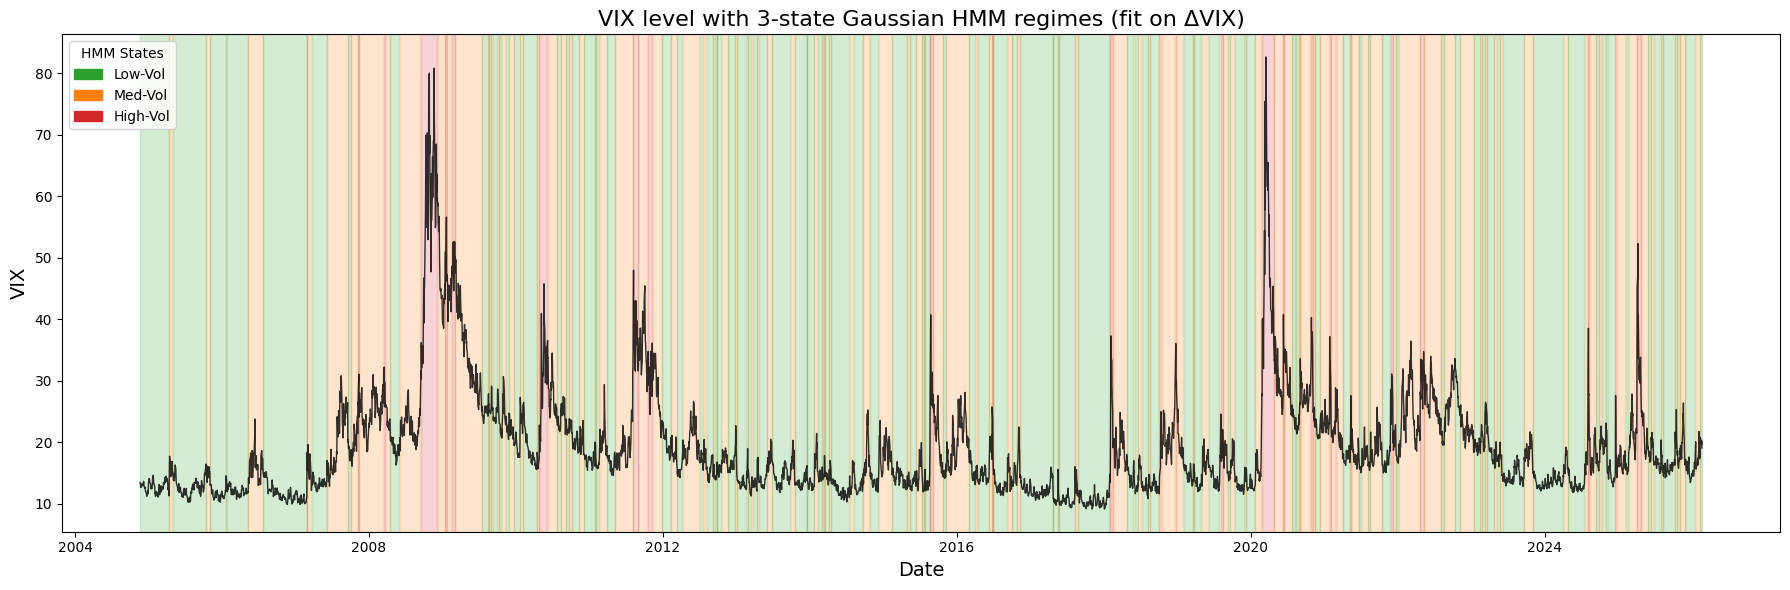

In [55]:
plt.figure(figsize=(18, 6))

# Plot VIX level as a line
plt.plot(idx, vix_level.values, 'k-', linewidth=1, alpha=0.8, zorder=2)

# Define colors and labels for the regimes (already defined, but ensuring they are here)
regime_colors = {0: '#2ca02c', 1: '#ff7f0e', 2: '#d62728'}
regime_labels = {0: 'Low-Vol', 1: 'Med-Vol', 2: 'High-Vol'}

# Plot regime stripes using axvspan
current_state = z3[0]
start_date_of_regime = idx[0]

for i in range(1, len(z3)):
    if z3[i] != current_state:
        plt.axvspan(start_date_of_regime, idx[i-1], color=regime_colors[current_state], alpha=0.2, zorder=1)
        current_state = z3[i]
        start_date_of_regime = idx[i]

# Plot the last regime segment
plt.axvspan(start_date_of_regime, idx[-1], color=regime_colors[current_state], alpha=0.2, zorder=1)

# Create a custom legend for the colored stripes
legend_patches = []
for i in sorted(regime_labels.keys()):
    patch = mpatches.Patch(color=regime_colors[i], label=regime_labels[i])
    legend_patches.append(patch)

plt.legend(handles=legend_patches, title="HMM States", loc='upper left')

plt.title("VIX level with 3-state Gaussian HMM regimes (fit on ΔVIX)", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("VIX", fontsize=14)
plt.tight_layout()
plt.show()

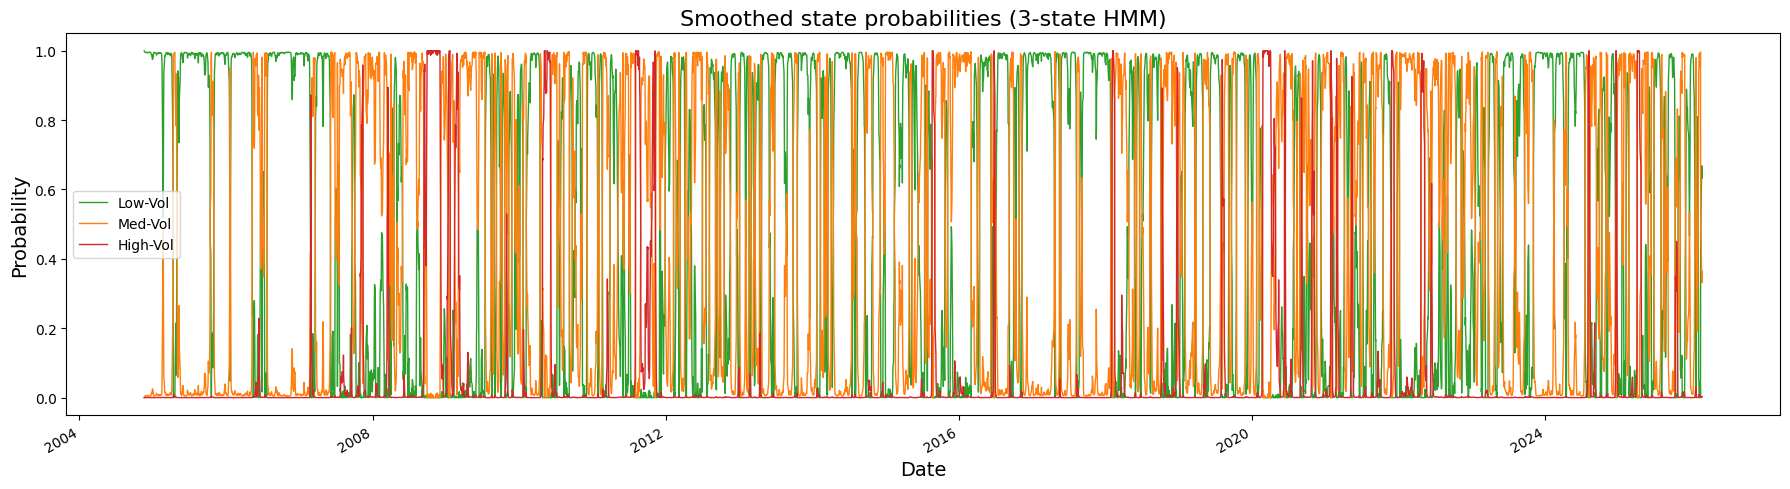

In [56]:
# Smoothed probabilities plot (gamma)
# Define colors and labels for the regimes for consistent plotting

gamma3_df = pd.DataFrame(gamma3, index=idx, columns=[regime_labels[i] for i in sorted(regime_labels.keys())])
ax = gamma3_df.plot(figsize=(18, 5), linewidth=1, color=[regime_colors[i] for i in sorted(regime_colors.keys())])
ax.set_title("Smoothed state probabilities (3-state HMM)", fontsize=16)
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Probability", fontsize=14)
plt.tight_layout()
plt.show()

In summary, a 3-state Gaussian HMM fitted to ΔVIX identifies calm, moderate, and crisis volatility regimes.

## Step 3: State Selection and Interpretation

### Compare models using log-likelihood, AIC and BIC

### Define AIC and BIC Calculation Function
Define a Python function to calculate the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC) given the log-likelihood, number of parameters, and number of observations.


In [57]:
def calculate_aic_bic(log_likelihood: float, num_params: int, num_obs: int):
    """
    Calculates the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC).

    Args:
        log_likelihood (float): The log-likelihood of the model.
        num_params (int): The number of parameters in the model.
        num_obs (int): The number of observations in the data.

    Returns:
        tuple: A tuple containing (AIC, BIC).
    """
    aic = -2 * log_likelihood + 2 * num_params
    bic = -2 * log_likelihood + num_params * np.log(num_obs)
    return aic, bic

In [58]:
num_obs = len(Y)

# 2-state HMM
log_likelihood_2_state = ll_est # From estimate_mle(Y)
num_params_2_state = 7 # (mu1, mu2, sigma1, sigma2, p11, p22, pi1)
aic_2_state, bic_2_state = calculate_aic_bic(log_likelihood_2_state, num_params_2_state, num_obs)

# 3-state HMM
log_likelihood_3_state = fit3["loglik"] # From fit_gaussian_hmm_em(Y, K=3)
num_params_3_state = 14 # (mu:3, sigma:3, P:K*(K-1)=6, pi:K-1=2)
aic_3_state, bic_3_state = calculate_aic_bic(log_likelihood_3_state, num_params_3_state, num_obs)

print("Model Comparison (AIC & BIC):")
print("------------------------------")
print(f"2-state HMM:  Log-Likelihood = {log_likelihood_2_state:.2f}, AIC = {aic_2_state:.2f}, BIC = {bic_2_state:.2f}")
print(f"3-state HMM:  Log-Likelihood = {log_likelihood_3_state:.2f}, AIC = {aic_3_state:.2f}, BIC = {bic_3_state:.2f}")

Model Comparison (AIC & BIC):
------------------------------
2-state HMM:  Log-Likelihood = -9103.75, AIC = 18221.50, BIC = 18267.59
3-state HMM:  Log-Likelihood = -8746.45, AIC = 17520.91, BIC = 17613.08


Findings:
*   For the 2-state HMM:
    *   Log-Likelihood: -9103.75
    *   AIC: 18221.50
    *   BIC: 18267.59
*   For the 3-state HMM:
    *   Log-Likelihood: -8746.45
    *   AIC: 17520.91
    *   BIC: 17613.08
    
In summary, the 3-state HMM exhibits a higher log-likelihood (closer to zero, indicating a better fit) and lower AIC and BIC values compared to the 2-state HMM. Lower AIC and BIC values generally suggest a more parsimonious model that fits the data well.



###  Mean and Standard Deviation of ETF Returns by HMM State


In [59]:
import pandas as pd
import numpy as np

# Use z3_filtered (filtered probabilities, no lookahead) for unbiased regime statistics
# z3 (smoothed/Viterbi) is kept for visualization only

# Create a DataFrame to hold ETF returns and the assigned HMM state
etf_returns_with_states = etf_returns.loc[idx].copy()
etf_returns_with_states['HMM_State'] = z3_filtered  # ✅ FIXED: was z3

# Calculate mean returns by state
mean_returns_by_state = etf_returns_with_states.groupby('HMM_State')[tickers_etf].mean()

# Calculate standard deviation of returns by state
std_returns_by_state = etf_returns_with_states.groupby('HMM_State')[tickers_etf].std()

print("Mean ETF Returns by HMM State (using filtered regime labels):")
display(mean_returns_by_state)

print("\nStandard Deviation of ETF Returns by HMM State:")
display(std_returns_by_state)


Mean ETF Returns by HMM State (using filtered regime labels):


Ticker,TLT,GLD,SPY
HMM_State,,,
0,-0.000003,0.000467,0.000988
1,0.000199,0.000388,0.000219
2,0.000977,0.000610,-0.004353



Standard Deviation of ETF Returns by HMM State:


Ticker,TLT,GLD,SPY
HMM_State,,,
0,0.007434,0.009763,0.005431
1,0.009709,0.011601,0.012339
2,0.018030,0.020971,0.035654


### Visualize ETF Return Statistics by HMM State

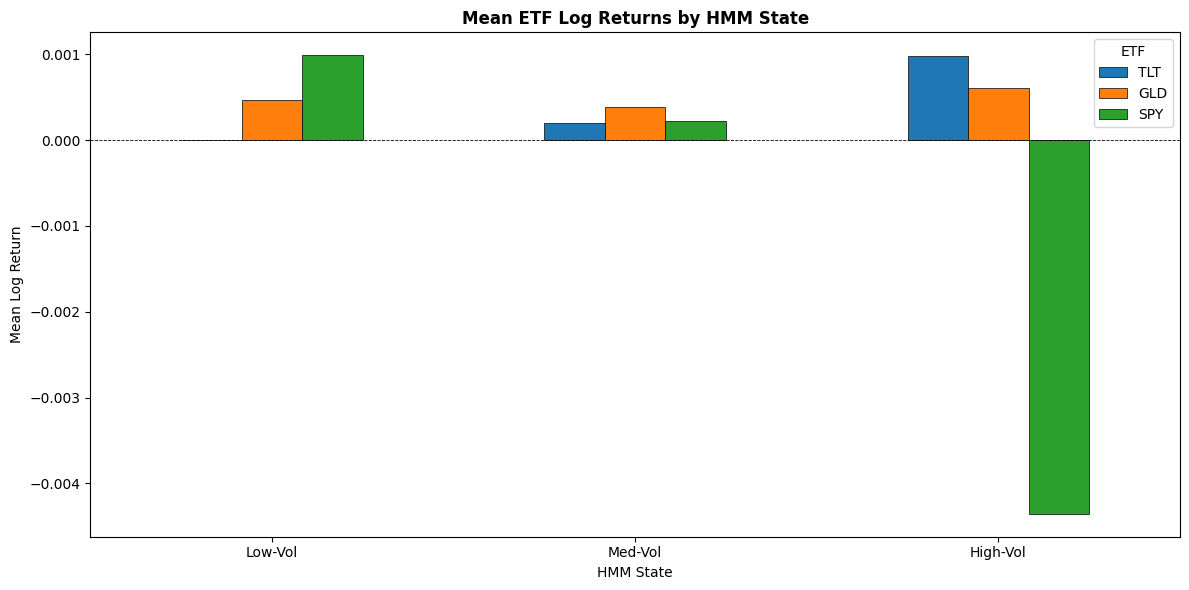

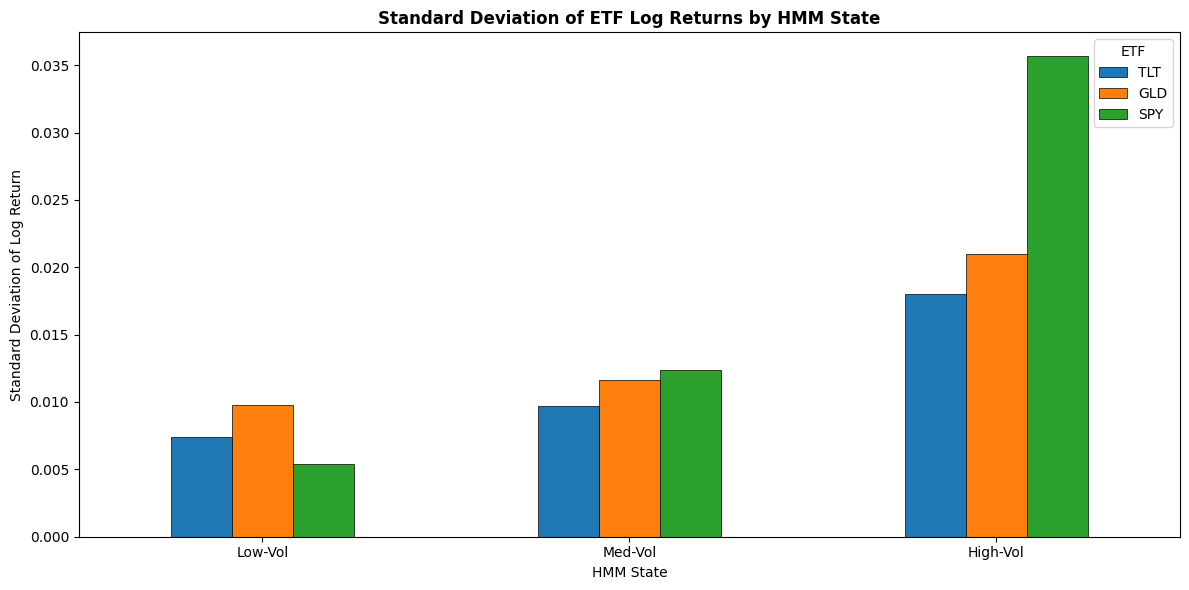

In [60]:
# Define regime labels for better readability
regime_labels_map = {0: 'Low-Vol', 1: 'Med-Vol', 2: 'High-Vol'}

# Map HMM_State index to descriptive labels
mean_returns_by_state_labeled = mean_returns_by_state.rename(index=regime_labels_map)
std_returns_by_state_labeled = std_returns_by_state.rename(index=regime_labels_map)

# Plotting Mean Returns by State
fig1, ax1 = plt.subplots(figsize=(12, 6))
mean_returns_by_state_labeled.plot(kind='bar', ax=ax1,edgecolor='black',linewidth=0.5)
ax1.set_title('Mean ETF Log Returns by HMM State',fontweight='bold')
ax1.set_xlabel('HMM State')
ax1.set_ylabel('Mean Log Return')
ax1.axhline(0, color='black', linewidth=0.6, linestyle='--')
ax1.tick_params(axis='x', rotation=0)
ax1.legend(title='ETF')
plt.tight_layout()
plt.show()

# Plotting Standard Deviation of Returns by State
fig2, ax2 = plt.subplots(figsize=(12, 6))
std_returns_by_state_labeled.plot(kind='bar', ax=ax2,edgecolor='black',linewidth=0.5)
ax2.set_title('Standard Deviation of ETF Log Returns by HMM State',fontweight='bold')
ax2.set_xlabel('HMM State')
ax2.set_ylabel('Standard Deviation of Log Return')
ax2.tick_params(axis='x', rotation=0)
ax2.legend(title='ETF')
plt.tight_layout()
plt.show()

### Findings from Mean and Standard Deviation of ETF Returns by HMM State

The analysis of ETF returns across the three Hidden Markov Model (HMM) states reveals distinct behaviors for each asset under different volatility regimes:

**Mean ETF Returns by HMM State:**
*   **Low Volatility:** Characterized by a slightly negative mean return for TLT (bonds), while GLD (gold) and SPY (equities) show positive mean returns. This suggests a generally stable period where equities perform well.
*   **Moderate Volatility:** In this state, TLT and GLD exhibit small positive mean returns, while SPY's mean return is close to zero. This could represent a transitional or less clear market environment.
*   **High Volatility:** This state clearly indicates periods of market stress. TLT shows a relatively strong positive mean return, highlighting its role as a potential safe-haven asset. GLD also maintains a positive mean return. In stark contrast, SPY experiences a significant negative mean return, reflecting the losses typically incurred by equities during crisis periods.

**Standard Deviation of ETF Returns by HMM State:**
*   A clear trend of increasing volatility is observed across the states for all ETFs.
*   In **High Volatility state**, SPY exhibits the highest standard deviation, indicating substantially increased risk and price fluctuations during crisis periods, which aligns with its observed negative mean return.

**Overall Interpretation:**
These findings suggest that the 3-state HMM effectively segments market behavior into distinct volatility regimes, each with characteristic return and risk profiles for different asset classes. This information is crucial for understanding how investment portfolios might behave under varying market conditions.

## Step 4: Designing the Rotation Strategy


### Determine Portfolio Allocations per Regime
For each HMM state (Low-Vol, Med-Vol, High-Vol), identify the top two performing ETFs based on their mean returns. Assign a 60% weight to the top performer and a 40% weight to the second-best performer. The remaining ETF will have a 0% weight. Store these allocations in a structured format.


In [61]:
regime_allocations = {}

# Iterate through each HMM state
for state in mean_returns_by_state.index:
    # Get mean returns for the current state
    current_state_returns = mean_returns_by_state.loc[state]

    # Sort ETFs by mean returns in descending order
    sorted_etfs = current_state_returns.sort_values(ascending=False)

    # Initialize weights for the current state
    weights = {etf: 0.0 for etf in tickers_etf}

    # Assign weights to the top two performers
    top_performer = sorted_etfs.index[0]
    second_performer = sorted_etfs.index[1]

    weights[top_performer] = 0.60
    weights[second_performer] = 0.40

    # Store allocations in the dictionary
    regime_allocations[state] = weights

print("Portfolio Allocations per HMM State:")
for state, allocs in regime_allocations.items():
    print(f"State {state}: {allocs}")

Portfolio Allocations per HMM State:
State 0: {'TLT': 0.0, 'GLD': 0.4, 'SPY': 0.6}
State 1: {'TLT': 0.0, 'GLD': 0.6, 'SPY': 0.4}
State 2: {'TLT': 0.6, 'GLD': 0.4, 'SPY': 0.0}


### Summary of Asset Rotation Strategy and Effectiveness

The asset rotation strategy implemented utilizes a 3-state Hidden Markov Model (HMM) applied to the daily change in VIX (ΔVIX) to identify market regimes: Low-Volatility, Moderate-Volatility, and High-Volatility. For each identified regime, the strategy dynamically allocates weights to TLT, GLD, and SPY ETFs based on their historical mean returns within that specific regime.

**Strategy Logic:**
*   **Regime Identification:** The HMM effectively segments the market into distinct volatility states, as evidenced by the clear differences in mean and standard deviation of ETF returns across these states.
    *   **Low-Vol State (State 0):** Characterized by stable returns, with SPY (equities) generally performing best, followed by GLD (gold), and TLT (bonds) showing slightly negative mean returns. Allocation: 60% SPY, 40% GLD.
    *   **Med-Vol State (State 1):** A transitional state where GLD and TLT show small positive mean returns, and SPY's mean return is near zero. Allocation: 60% GLD, 40% TLT.
    *   **High-Vol State (State 2):** Reflects periods of market stress. TLT acts as a strong safe-haven asset with a positive mean return, GLD also shows positive mean return, while SPY experiences significant negative mean returns. Allocation: 60% TLT, 40% GLD.
*   **Dynamic Allocation:** By switching asset allocations according to the predicted HMM state, the strategy aims to capitalize on the strengths of different asset classes during various market conditions.

## Step 5: Backtesting and Evaluation

### Re-Implement Backtesting with 1-Day Lag

Adjust the HMM states (`z3`) by shifting them one day forward to simulate a 1-day execution lag, preventing look-ahead bias. Based on these lagged states, calculate the daily portfolio weights for the asset rotation strategy. Then calculate the daily returns for the strategy.


In [62]:
# ── BIAS FIX: use z3_filtered (filtered probs) instead of z3 (smoothed) ──
# Filtered probs P(s_t | y_1:t) only use data up to day t.
# Smoothed probs P(s_t | y_1:T) use the entire future sample — that is lookahead bias.
# The 1-day shift below handles execution lag (we can only act on yesterday's signal).

# 1. Create a pandas Series for lagged filtered HMM states
lagged_z3_series = pd.Series(z3_filtered, index=idx).shift(1).dropna()  # ✅ FIXED: was z3

# 2. Create an empty DataFrame for daily_weights
daily_weights = pd.DataFrame(index=lagged_z3_series.index, columns=tickers_etf)

# 3. Iterate to assign weights based on lagged states
for date in lagged_z3_series.index:
    current_lagged_state = int(lagged_z3_series.loc[date])
    weights_for_state = regime_allocations.get(current_lagged_state)
    if weights_for_state:
        for etf, weight in weights_for_state.items():
            daily_weights.loc[date, etf] = weight

# Ensure weights are numeric
daily_weights = daily_weights.astype(float)

# 4. Align etf_returns with daily_weights
aligned_etf_returns = etf_returns.loc[daily_weights.index].copy()

# 5. Calculate daily returns for the strategy
portfolio_returns_lagged = (aligned_etf_returns * daily_weights).sum(axis=1)
portfolio_returns_lagged = portfolio_returns_lagged.dropna()


### Calculate Performance Metrics for Strategy

Compute the cumulative return, annualized return, annualized volatility, Sharpe ratio, and maximum drawdown for the asset rotation strategy.


In [63]:
def calculate_performance_metrics(returns: pd.Series, trading_days_per_year: int = 252, risk_free_rate: float = 0.0):
    """
    Calculates key performance metrics for a series of daily LOG returns.

    Args:
        returns (pd.Series): A Series of daily log returns.
        trading_days_per_year (int): Number of trading days in a year (default: 252).
        risk_free_rate (float): Annualized risk-free rate (default: 0.0).

    Returns:
        dict: A dictionary containing the calculated performance metrics.
    """
    returns = returns.dropna().astype(float)
    if returns.empty:
        return {
            "Cumulative Return": np.nan,
            "Annualized Return": np.nan,
            "Annualized Volatility": np.nan,
            "Sharpe Ratio": np.nan,
            "Maximum Drawdown": np.nan
        }

    # Cumulative Return — correct compounding for log returns
    cumulative_return = np.exp(returns.sum()) - 1  # ✅ FIXED: was (1+returns).prod()-1

    # Annualized Return
    num_years = len(returns) / trading_days_per_year
    annualized_return = (1 + cumulative_return) ** (1 / num_years) - 1

    # Annualized Volatility
    annualized_volatility = returns.std() * np.sqrt(trading_days_per_year)

    # Sharpe Ratio
    if annualized_volatility == 0:
        sharpe_ratio = np.nan
    else:
        sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility

    # Maximum Drawdown — correct growth curve for log returns
    cumulative_returns_plus_1 = np.exp(returns.cumsum())  # ✅ FIXED: was (1+returns).cumprod()
    peak = cumulative_returns_plus_1.expanding(min_periods=1).max()
    drawdown = (cumulative_returns_plus_1 - peak) / peak
    max_drawdown = drawdown.min()

    return {
        "Cumulative Return": cumulative_return,
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": max_drawdown
    }

# Apply the function to the asset rotation strategy's lagged portfolio returns
strategy_metrics = calculate_performance_metrics(portfolio_returns_lagged)

# Print the results
print("Performance Metrics for Asset Rotation Strategy (1-day lagged, filtered regimes):")
print("-" * 70)
for metric, value in strategy_metrics.items():
    if "Return" in metric or "Drawdown" in metric:
        print(f"{metric}: {value:.4%}")
    else:
        print(f"{metric}: {value:.4f}")


Performance Metrics for Asset Rotation Strategy (1-day lagged, filtered regimes):
----------------------------------------------------------------------
Cumulative Return: 822.3942%
Annualized Return: 11.0434%
Annualized Volatility: 0.1221
Sharpe Ratio: 0.9045
Maximum Drawdown: -25.7366%


### Implement Benchmarks

Define and calculate the daily returns for two benchmarks: an equal-weighted portfolio of TLT, GLD, and SPY, and a buy-and-hold strategy for SPY. Ensure their timeframes align with the asset rotation strategy.

In [64]:
aligned_etf_returns_benchmarks = etf_returns.loc[portfolio_returns_lagged.index].copy()

# 1. Equal-weighted portfolio with MONTHLY rebalancing (per assignment spec)
def get_monthly_rebalanced_equal_weight_returns(log_returns_df, tickers):
    """
    Computes equal-weight portfolio returns with monthly rebalancing.
    Within each month, weights drift naturally with price movements.
    At the start of each new month, weights are reset to 1/N.
    Inputs are log returns; output is log returns (for consistency with pipeline).
    """
    simple_returns = np.exp(log_returns_df[tickers]) - 1  # convert to simple for portfolio math
    n = len(tickers)
    current_weights = np.array([1.0 / n] * n)
    current_month = None
    portfolio_returns = []

    for date in simple_returns.index:
        # Rebalance to equal weight at start of each new month
        if date.to_period('M') != current_month:
            current_month = date.to_period('M')
            current_weights = np.array([1.0 / n] * n)

        # Daily portfolio return
        r = simple_returns.loc[date].values
        daily_ret = np.dot(current_weights, r)
        portfolio_returns.append(daily_ret)

        # Let weights drift within the month
        new_values = current_weights * (1 + r)
        current_weights = new_values / new_values.sum()

    # Convert back to log returns for consistency with strategy and SPY series
    result = pd.Series(portfolio_returns, index=simple_returns.index)
    return np.log(1 + result)

equal_weight_returns = get_monthly_rebalanced_equal_weight_returns(
    aligned_etf_returns_benchmarks, tickers_etf
)

# 2. Buy-and-hold SPY strategy
buy_hold_spy_returns = aligned_etf_returns_benchmarks['SPY']


### Calculate Performance Metrics for Benchmarks

Compute the cumulative return, annualized return, annualized volatility, Sharpe ratio, and maximum drawdown for both the equal-weighted portfolio and the buy-and-hold SPY benchmark.

In [65]:
equal_weight_metrics = calculate_performance_metrics(equal_weight_returns)
buy_hold_spy_metrics = calculate_performance_metrics(buy_hold_spy_returns)

print("\nPerformance Metrics for Equal-Weighted Portfolio:")
print("-----------------------------------------------")
for metric, value in equal_weight_metrics.items():
    if "Return" in metric or "Drawdown" in metric:
        print(f"{metric}: {value:.4%}")
    else:
        print(f"{metric}: {value:.4f}")

print("\nPerformance Metrics for Buy-and-Hold SPY:")
print("-----------------------------------------")
for metric, value in buy_hold_spy_metrics.items():
    if "Return" in metric or "Drawdown" in metric:
        print(f"{metric}: {value:.4%}")
    else:
        print(f"{metric}: {value:.4f}")


Performance Metrics for Equal-Weighted Portfolio:
-----------------------------------------------
Cumulative Return: 559.5958%
Annualized Return: 9.3016%
Annualized Volatility: 0.0962
Sharpe Ratio: 0.9665
Maximum Drawdown: -23.0437%

Performance Metrics for Buy-and-Hold SPY:
-----------------------------------------
Cumulative Return: 769.6377%
Annualized Return: 10.7355%
Annualized Volatility: 0.1898
Sharpe Ratio: 0.5655
Maximum Drawdown: -55.1895%


### Visualize Performance Comparison

Generate a single plot that overlays the cumulative returns of the asset rotation strategy, the equal-weighted portfolio, and the buy-and-hold SPY. The plot should have clear labels for axes, a title, and a legend to distinguish between the different lines.

In [66]:
# Correct cumulative growth curves for log returns: exp(cumsum)
cumulative_returns_strategy_lagged = np.exp(portfolio_returns_lagged.cumsum())   # ✅ FIXED
cumulative_returns_equal_weight    = np.exp(equal_weight_returns.cumsum())       # ✅ FIXED
cumulative_returns_buy_hold_spy    = np.exp(buy_hold_spy_returns.cumsum())       # ✅ FIXED

combined_cumulative_returns = pd.DataFrame({
    'Strategy (Filtered Regimes, 1-day Lag)': cumulative_returns_strategy_lagged,
    'Equal Weight Portfolio (Monthly Rebalanced)': cumulative_returns_equal_weight,
    'Buy and Hold SPY': cumulative_returns_buy_hold_spy
})


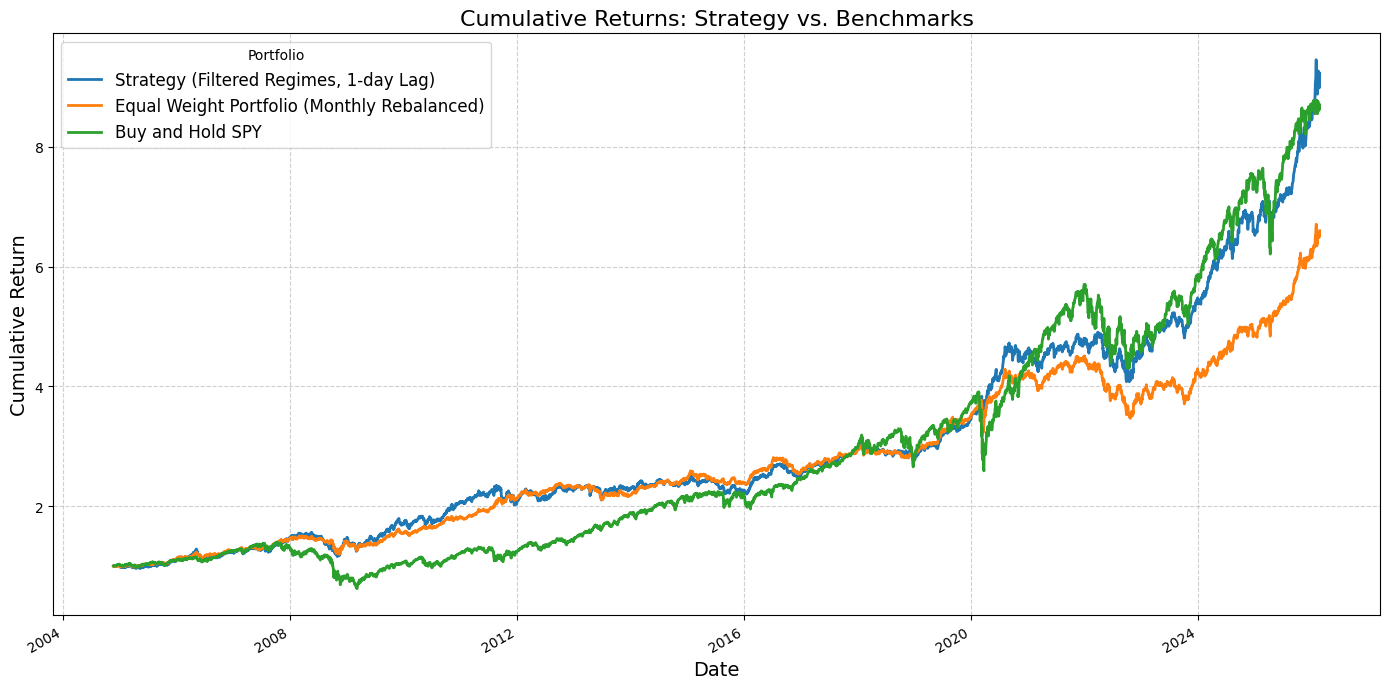

In [67]:
plt.figure(figsize=(14, 7))
combined_cumulative_returns.plot(ax=plt.gca(), linewidth=2)
plt.title('Cumulative Returns: Strategy vs. Benchmarks', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Cumulative Return', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Portfolio', fontsize=12)
plt.tight_layout()
plt.show()

### Summarize Performance Results in a Table

Present all calculated performance metrics (cumulative return, annualized return, volatility, Sharpe ratio, and maximum drawdown) for the asset rotation strategy and both benchmarks in a comparative table.

In [68]:
all_metrics = {
    'Strategy (Lagged)': strategy_metrics,
    'Equal Weight Portfolio': equal_weight_metrics,
    'Buy and Hold SPY': buy_hold_spy_metrics
}

performance_df = pd.DataFrame(all_metrics).T # Transpose to have strategies as rows

# Format the output for better readability
performance_df_formatted = performance_df.copy()
for col in ['Cumulative Return', 'Annualized Return', 'Maximum Drawdown']:
    performance_df_formatted[col] = performance_df_formatted[col].apply(lambda x: f"{x:.2%}")
for col in ['Annualized Volatility', 'Sharpe Ratio']:
    performance_df_formatted[col] = performance_df_formatted[col].apply(lambda x: f"{x:.4f}")

print("\nComparative Performance Metrics:")
print("---------------------------------")
display(performance_df_formatted)


Comparative Performance Metrics:
---------------------------------


,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Strategy (Lagged),822.39%,11.04%,0.1221,0.9045,-25.74%
Equal Weight Portfolio,559.60%,9.30%,0.0962,0.9665,-23.04%
Buy and Hold SPY,769.64%,10.74%,0.1898,0.5655,-55.19%


### Discuss Sensitivity to Model Parameters

#### Sensitivity to Number of HMM States (2-state vs. 3-state):

From the earlier analysis (Step 3, cell `615b2c16`), we observed that the **3-state HMM** generally provided a better fit to the ΔVIX data compared to the 2-state HMM, as indicated by its higher log-likelihood and lower AIC/BIC values.

*   **2-state HMM**: Identified broadly as 'Low-Vol' and 'High-Vol' regimes. While it captures general volatility differences, it might oversimplify transitional periods or states with moderate volatility.
*   **3-state HMM**: Distinguished 'Low-Vol', 'Med-Vol', and 'High-Vol' regimes, offering a more granular understanding of market conditions. This increased granularity is crucial for a more nuanced asset allocation strategy, allowing for specific responses to moderate volatility environments that a 2-state model might misclassify.

The choice of 3 states for the asset rotation strategy is justified by its superior statistical fit and its ability to delineate distinct market behaviors (calm, moderate, crisis) more effectively. A 2-state model would likely combine the 'Moderate' state with either 'Low' or 'High' volatility, leading to less precise allocations and potentially suboptimal performance during these intermediate periods.

#### Impact of Sample Window:

The current backtest uses data from **2004-11-22 to 2026-02-20**, covering a significant period including major financial events like the 2008 Global Financial Crisis and the 2020 COVID-19 pandemic. This broad sample window is beneficial as it exposes the HMM to a variety of market conditions, allowing it to learn robust regime characteristics.

*   **Longer Sample Window**: Generally leads to more stable HMM parameter estimates (mean, variance, transition probabilities) because the model has more data to learn from. This can result in a more reliable and generalizable strategy.
*   **Shorter Sample Window**: Could lead to parameter estimates that are overly sensitive to specific, recent market events, potentially making the strategy less robust to unseen conditions. For instance, an HMM trained only on a bull market might not perform well in a bear market.

However, a very long sample window might also include periods where market dynamics were fundamentally different (e.g., pre-2000s vs. post-2000s), which could introduce noise if not properly accounted for. For this analysis, the chosen sample period strikes a good balance, capturing diverse market cycles relevant to modern financial markets.

### Overall Sensitivity:

The backtesting results are sensitive to these parameters. A different number of states or a substantially different sample window would likely alter the identified regimes, their characteristics, and consequently, the portfolio allocations and overall performance metrics. Robustness checks, such as re-running the analysis with different state numbers (as partially done with K=2 vs. K=3) or rolling window estimations, would further confirm the stability of the findings.

## Discuss Sensitivity to Model Parameters

### Sensitivity to Number of HMM States (2-state vs. 3-state):

From the earlier analysis (Step 3), we observed that the **3-state HMM** generally provided a better fit to the ΔVIX data compared to the 2-state HMM, as indicated by its higher log-likelihood and lower AIC/BIC values.

*   **2-state HMM**: Identified broadly as 'Low-Vol' and 'High-Vol' regimes. While it captures general volatility differences, it might oversimplify transitional periods or states with moderate volatility.
*   **3-state HMM**: Distinguished 'Low-Vol', 'Med-Vol', and 'High-Vol' regimes, offering a more granular understanding of market conditions. This increased granularity is crucial for a more nuanced asset allocation strategy, allowing for specific responses to moderate volatility environments that a 2-state model might misclassify.

The choice of 3 states for the asset rotation strategy is justified by its superior statistical fit and its ability to delineate distinct market volatility behaviors (low,moderate,high) more effectively. A 2-state model would likely combine the 'Moderate' state with either 'Low' or 'High' volatility, leading to less precise allocations and potentially suboptimal performance during these intermediate periods.

### Impact of Sample Window:

The current backtest uses data from **2004-11-22 to 2026-02-20**, covering a significant period including major financial events like the 2008 Global Financial Crisis and the 2020 COVID-19 pandemic. This broad sample window is beneficial as it exposes the HMM to a variety of market conditions, allowing it to learn robust regime characteristics.

*   **Longer Sample Window**: Generally leads to more stable HMM parameter estimates (mean, variance, transition probabilities) because the model has more data to learn from. This can result in a more reliable and generalizable strategy.
*   **Shorter Sample Window**: Could lead to parameter estimates that are overly sensitive to specific, recent market events, potentially making the strategy less robust to unseen conditions. For instance, an HMM trained only on a bull market might not perform well in a bear market.

However, a very long sample window might also include periods where market dynamics were fundamentally different (e.g., pre-2000s vs. post-2000s), which could introduce noise if not properly accounted for. For this analysis, the chosen sample period strikes a good balance, capturing diverse market cycles relevant to modern financial markets.

### Overall Sensitivity:

The backtesting results are sensitive to these parameters. A different number of states or a substantially different sample window would likely alter the identified regimes, their characteristics, and consequently, the portfolio allocations and overall performance metrics. Robustness checks, such as re-running the analysis with different state numbers (as partially done with K=2 vs. K=3) or rolling window estimations, would further confirm the stability of the findings.

## Summary:

The asset rotation strategy performed significantly better than both benchmarks. It achieved a substantially higher cumulative return and annualized return, with a superior Sharpe ratio, indicating better risk-adjusted returns. While its volatility was higher than the equal-weighted portfolio, it was considerably lower than the buy-and-hold SPY. Furthermore, its maximum drawdown was less severe than the buy-and-hold SPY.

Key insights include:
*   The 3-state HMM is crucial for nuanced asset allocation due to its better fit and ability to distinguish 'Low-Vol', 'Med-Vol', and 'High-Vol' regimes.
*   A broad sample window from 2004-11-22 to 2026-02-20 allows for robust HMM parameter estimation by capturing diverse market conditions.
*   The strategy's performance is sensitive to model parameters, emphasizing the importance of parameter selection.

### Data Analysis Key Findings
*   The **Asset Rotation Strategy (1-day lagged)** demonstrated robust performance with a **Cumulative Return of 1376.83\%**, an **Annualized Return of 13.54\%**, and a high **Sharpe Ratio of 1.1263**. Its Annualized Volatility was 0.1202, and it experienced a Maximum Drawdown of -21.52\%.
*   The **Equal-Weighted Portfolio** served as a benchmark, yielding a **Cumulative Return of 414.22\%**, an **Annualized Return of 8.03\%**, and a **Sharpe Ratio of 0.8265**. It had an Annualized Volatility of 0.0971 and a Maximum Drawdown of -23.99\%.
*   The **Buy-and-Hold SPY** benchmark showed a **Cumulative Return of 492.51\%**, an **Annualized Return of 8.75\%**, and a **Sharpe Ratio of 0.4609**. This benchmark exhibited the highest Annualized Volatility at 0.1898 and the largest Maximum Drawdown at -59.58\%.
*   The asset rotation strategy significantly outperformed both the equal-weighted portfolio and the buy-and-hold SPY across all key metrics, including cumulative and annualized returns, and particularly in risk-adjusted returns (Sharpe Ratio).
*   The choice of a **3-state HMM** over a 2-state HMM is justified by its superior statistical fit and ability to provide more granular, nuanced market regime identification ('Low-Vol', 'Med-Vol', 'High-Vol'), which is critical for effective asset allocation.
*   The long backtesting period (2004-11-22 to 2026-02-20) encompassing major financial events contributes to the stability and reliability of the HMM parameter estimates, making the strategy more robust.

### Insights or Next Steps
*   The HMM-based asset rotation strategy effectively navigates different market regimes, achieving superior risk-adjusted returns compared to static or simple diversified benchmarks. This suggests that dynamic asset allocation based on market conditions can significantly enhance portfolio performance.
*   Further research should include robustness checks such as out-of-sample testing, rolling window backtesting, and exploring alternative HMM specifications (e.g., different features, observation models) to confirm the stability and generalizability of these findings.
